# Tema : Modelos de Intervención y Detección de Valores Atípicos
![](src/img/logo_utb.png){width=40%}
![](src/img/logo_etd.png){width=40%}
- **Profesor:**
- **Fernando Salcedo Mejía, Eco Msc.**
- Programa de Ciencias de Datos | Escuela de transformación digital.
- 2026-1

## Contenido

1. Modelos de intervención
    - Ejemplo 1. Serie temporal interrumpida (ITR) con datos de pasajeros aéreos
    - Ejemplo 2. Efecto de la pandemia del COVID-19 en el desempleo de Colombia
    - Ejemplo 3. Diferencias en diferencias con datos simulados
2. Detección de valores atípicos
    - Ejemplo 4. Tiempos extraños en la tasa de desempleo de Colombia
    - Ejemplo 5. Series extrañas en el turismo de Australia
    - Ejemplo 6. Vigilancia de la tasa de desempleo de Colombia

Los ejemplos siguen el enfoque de Hyndman y Athanasopoulos (2021), *Forecasting: principles and practice*, con los paquetes `tsibble`, `fable` y `feasts`.

## Librerías necesarias

In [1]:
# Instalar todas las librerias necesarias previamente desde r-requirements.txt
suppressPackageStartupMessages({
  library(tidyverse)
  library(tsibble)     # Estructura de datos para series de tiempo
  library(fable)       # Modelos TSLM, ARIMA y ETS
  library(feasts)      # Descomposición STL, ACF y características de series
  library(ggtime)      # Visualización
  library(sandwich)    # Errores estándar de Newey-West
  library(lmtest)      # Pruebas sobre los coeficientes con errores robustos
  library(patchwork)   # Combinar gráficos
})

# tamaño de los graficos
options(repr.plot.width = 8,
        repr.plot.height = 6,
        repr.plot.res = 300,
        repr.plot.pointsize = 14)

set_theme(theme_bw())

# 1. Modelos de intervención

## Ejemplo 1. Serie temporal interrumpida (ITR) con datos de pasajeros aéreos

- Usamos la serie mensual de pasajeros de aerolíneas internacionales (1949-1960). A partir de octubre de 1957 los datos se modificaron para simular una intervención que **reduce el número de pasajeros en un 30%**. Como conocemos el efecto verdadero, podemos comprobar si los modelos lo recuperan.
- El modelo de serie temporal interrumpida es

$$
Y_t = \beta_0 + \beta_1 t + \beta_2 D_t + \beta_3 \left[t - T_I \right] D_t + \eta_t
$$

- $D_t$ vale 0 antes de la intervención y 1 desde la intervención. En Hyndman y Athanasopoulos (2021, sección 7.4) esta variable se conoce como **variable escalón**.
- $\left[t - T_I \right] D_t$ vale 0 antes de la intervención y luego aumenta $0, 1, 2, \dots$. Permite un cambio de pendiente después de la intervención.
- $\beta_2$ mide el cambio de nivel y $\beta_3$ el cambio de pendiente.
- Como la estacionalidad de la serie crece con su nivel, modelamos el logaritmo de los pasajeros. Así, $\beta_2$ se interpreta como un cambio porcentual, que es $100\,(e^{\beta_2} - 1)\%$.

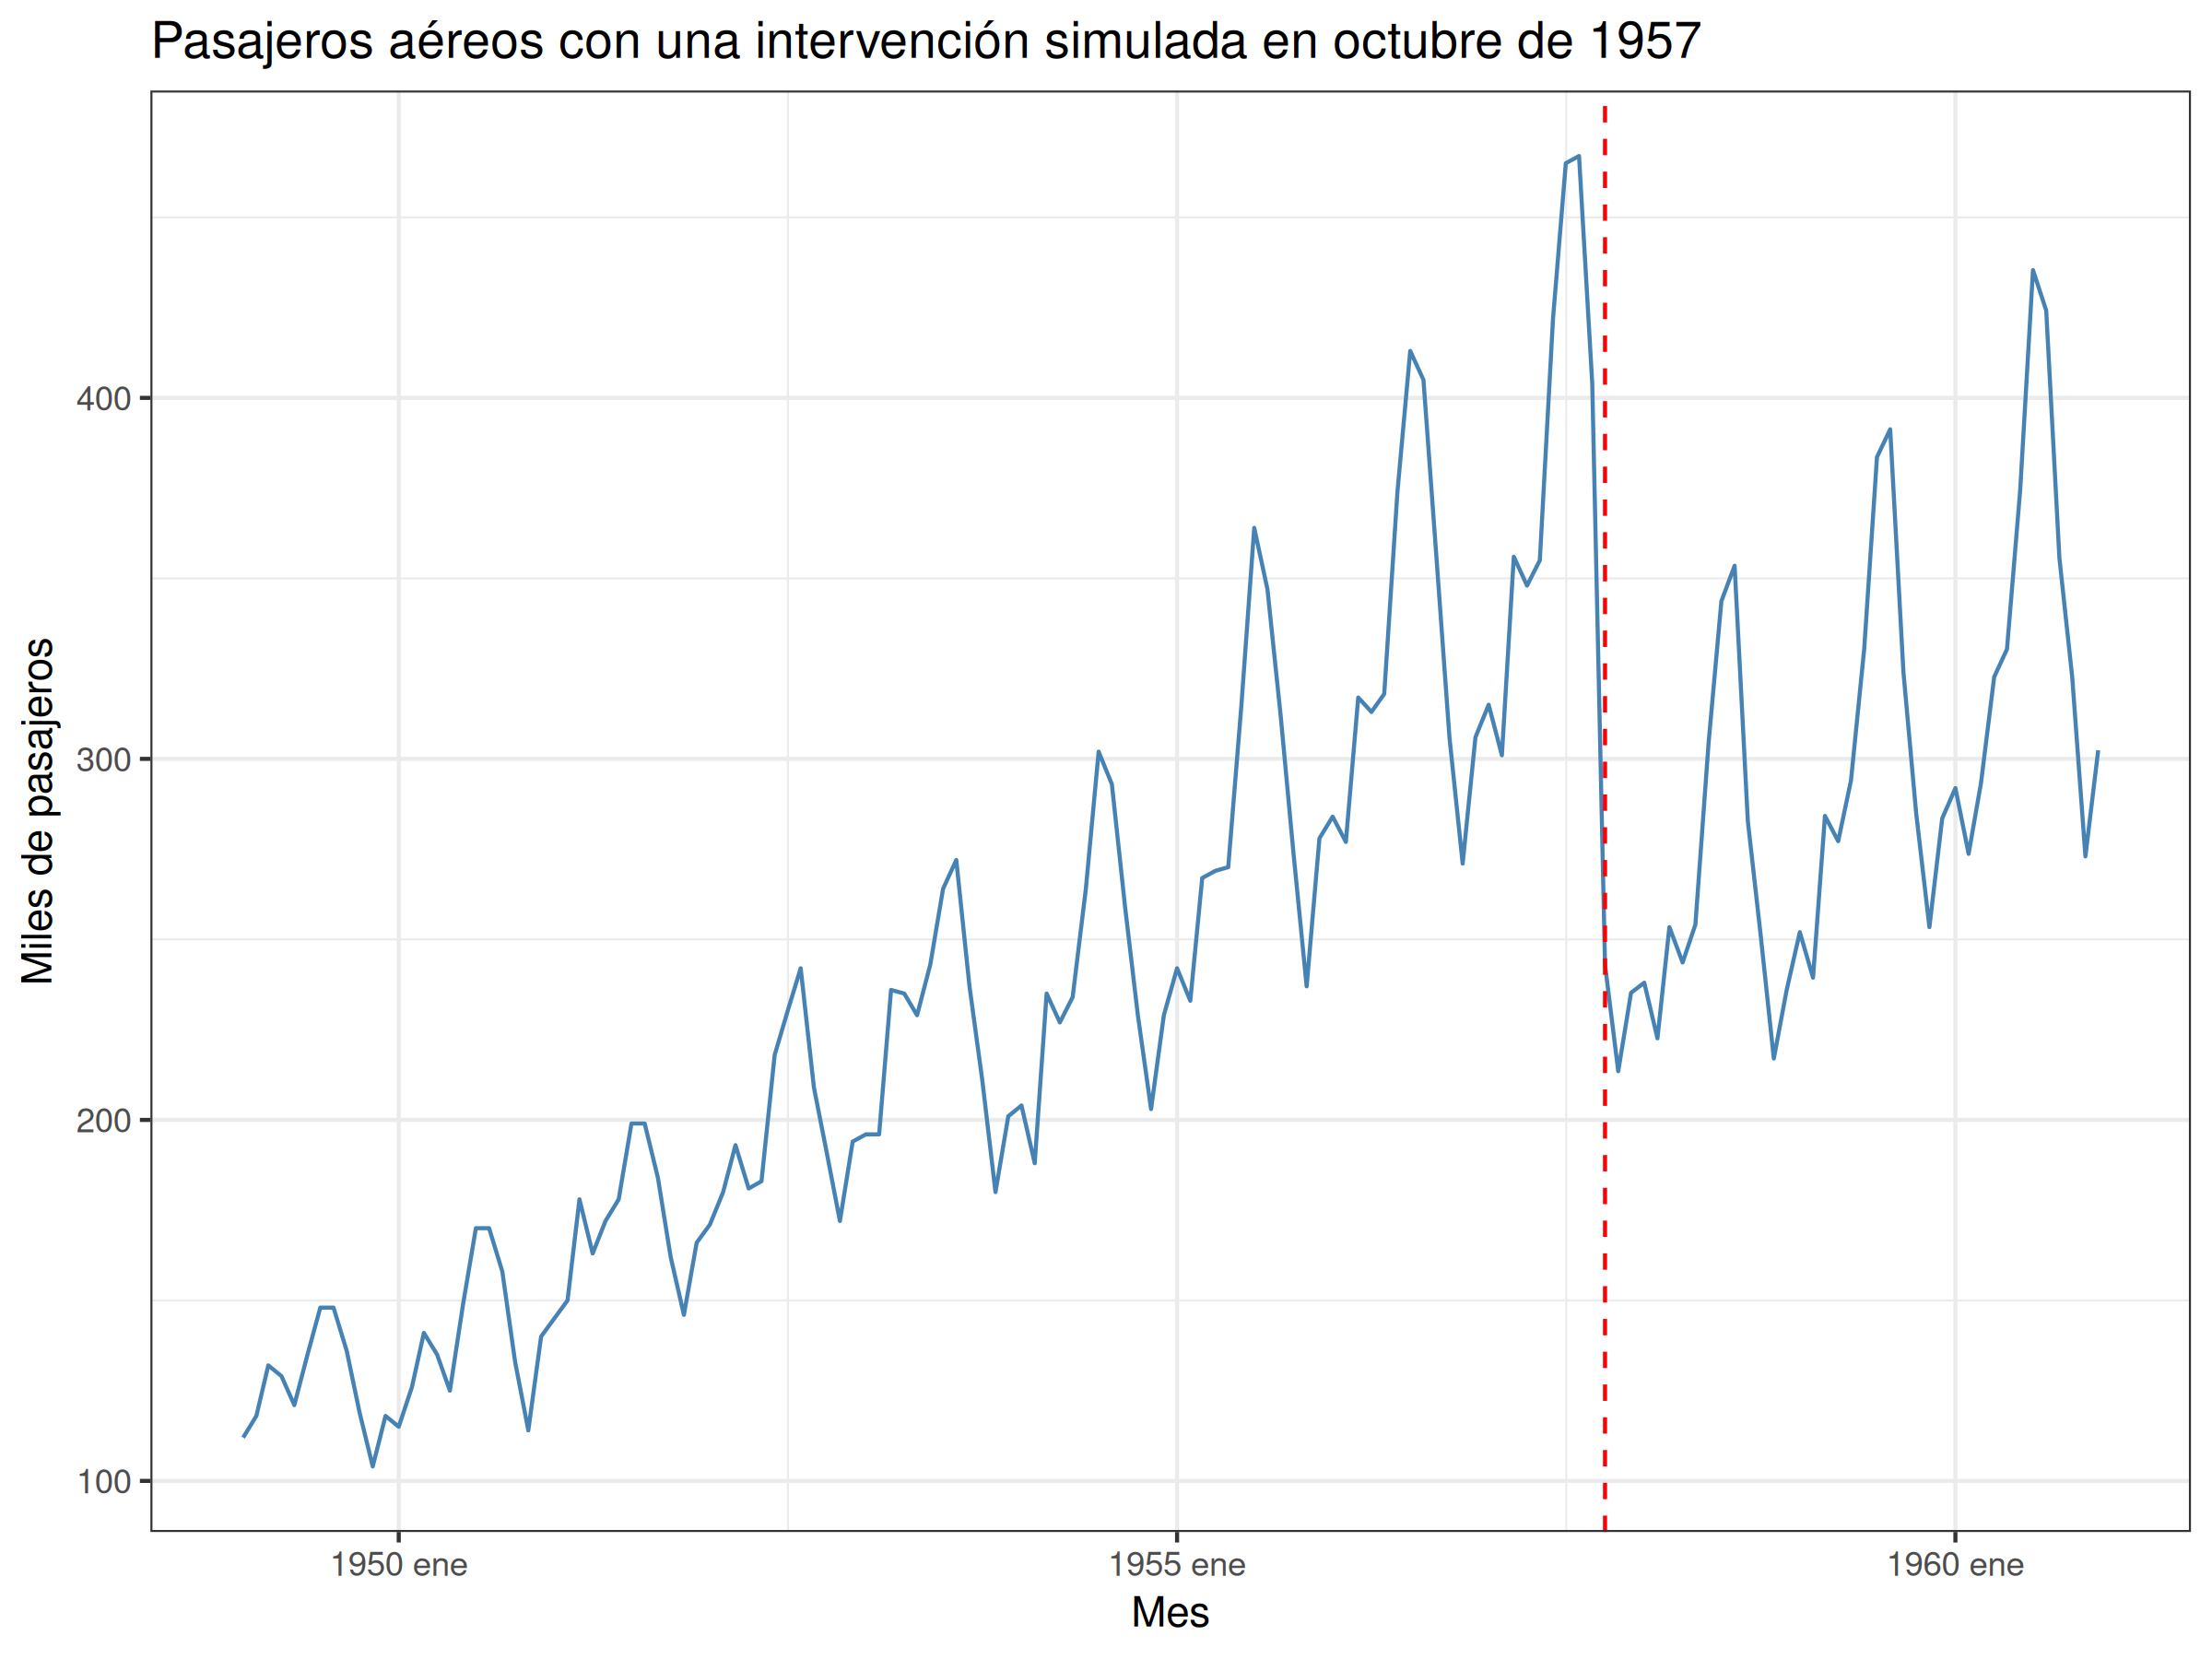

In [2]:
fecha_intervencion <- yearmonth("1957 Oct")

pasajeros <- read_csv("../data/AirPassengers_impact.csv", show_col_types = FALSE) |>
  mutate(Mes = yearmonth(ds)) |>
  select(Mes, Pasajeros = y) |>
  as_tsibble(index = Mes)

pasajeros |>
  autoplot(Pasajeros, colour = "steelblue") +
  geom_vline(xintercept = as.Date(fecha_intervencion), linetype = "dashed", colour = "red") +
  labs(title = "Pasajeros aéreos con una intervención simulada en octubre de 1957",
       x = "Mes", y = "Miles de pasajeros")

In [3]:
# Variables de la intervención
T_I <- which(pasajeros$Mes == fecha_intervencion)

pasajeros <- pasajeros |>
  mutate(
    t      = row_number(),             # tendencia
    D      = as.integer(t >= T_I),     # escalón, cambio de nivel
    t_post = pmax(0, t - T_I)          # cambio de pendiente
  )

pasajeros |> filter(t >= T_I - 2, t <= T_I + 3)

Mes,Pasajeros,t,D,t_post
<mth>,<dbl>,<int>,<int>,<dbl>
1957 ago,467.0,104,0,0
1957 sep,404.0,105,0,0
1957 oct,242.9,106,1,0
1957 nov,213.5,107,1,1
1957 dic,235.2,108,1,2
1958 ene,238.0,109,1,3


### Modelo ITR por mínimos cuadrados ordinarios

- Estimamos el modelo con `TSLM()`. Agregamos `season()`, que incluye variables indicadoras de cada mes para la estacionalidad.

In [4]:
fit_itr_mco <- pasajeros |>
  model(itr_mco = TSLM(log(Pasajeros) ~ t + season() + D + t_post))

report(fit_itr_mco)

Series: Pasajeros 
Model: TSLM 
Transformation: log(Pasajeros) 

Residuals:
     Min       1Q   Median       3Q      Max 
-0.11697 -0.02990  0.00274  0.02672  0.12077 

Coefficients:
                 Estimate Std. Error t value Pr(>|t|)    
(Intercept)     4.6830169  0.0153268 305.545  < 2e-16 ***
t               0.0111615  0.0001479  75.444  < 2e-16 ***
season()year2  -0.0225574  0.0187186  -1.205 0.230379    
season()year3   0.1071671  0.0187218   5.724 6.92e-08 ***
season()year4   0.0753957  0.0187270   4.026 9.62e-05 ***
season()year5   0.0725205  0.0187344   3.871 0.000171 ***
season()year6   0.1941641  0.0187439  10.359  < 2e-16 ***
season()year7   0.2976039  0.0187554  15.868  < 2e-16 ***
season()year8   0.2878064  0.0187691  15.334  < 2e-16 ***
season()year9   0.1426693  0.0187848   7.595 5.50e-12 ***
season()year10  0.0108739  0.0187397   0.580 0.562753    
season()year11 -0.1331497  0.0187482  -7.102 7.39e-11 ***
season()year12 -0.0195906  0.0187598  -1.044 0.298305    
D    

.model,lb_stat,lb_pvalue
<chr>,<dbl>,<dbl>
itr_mco,162.2774,0


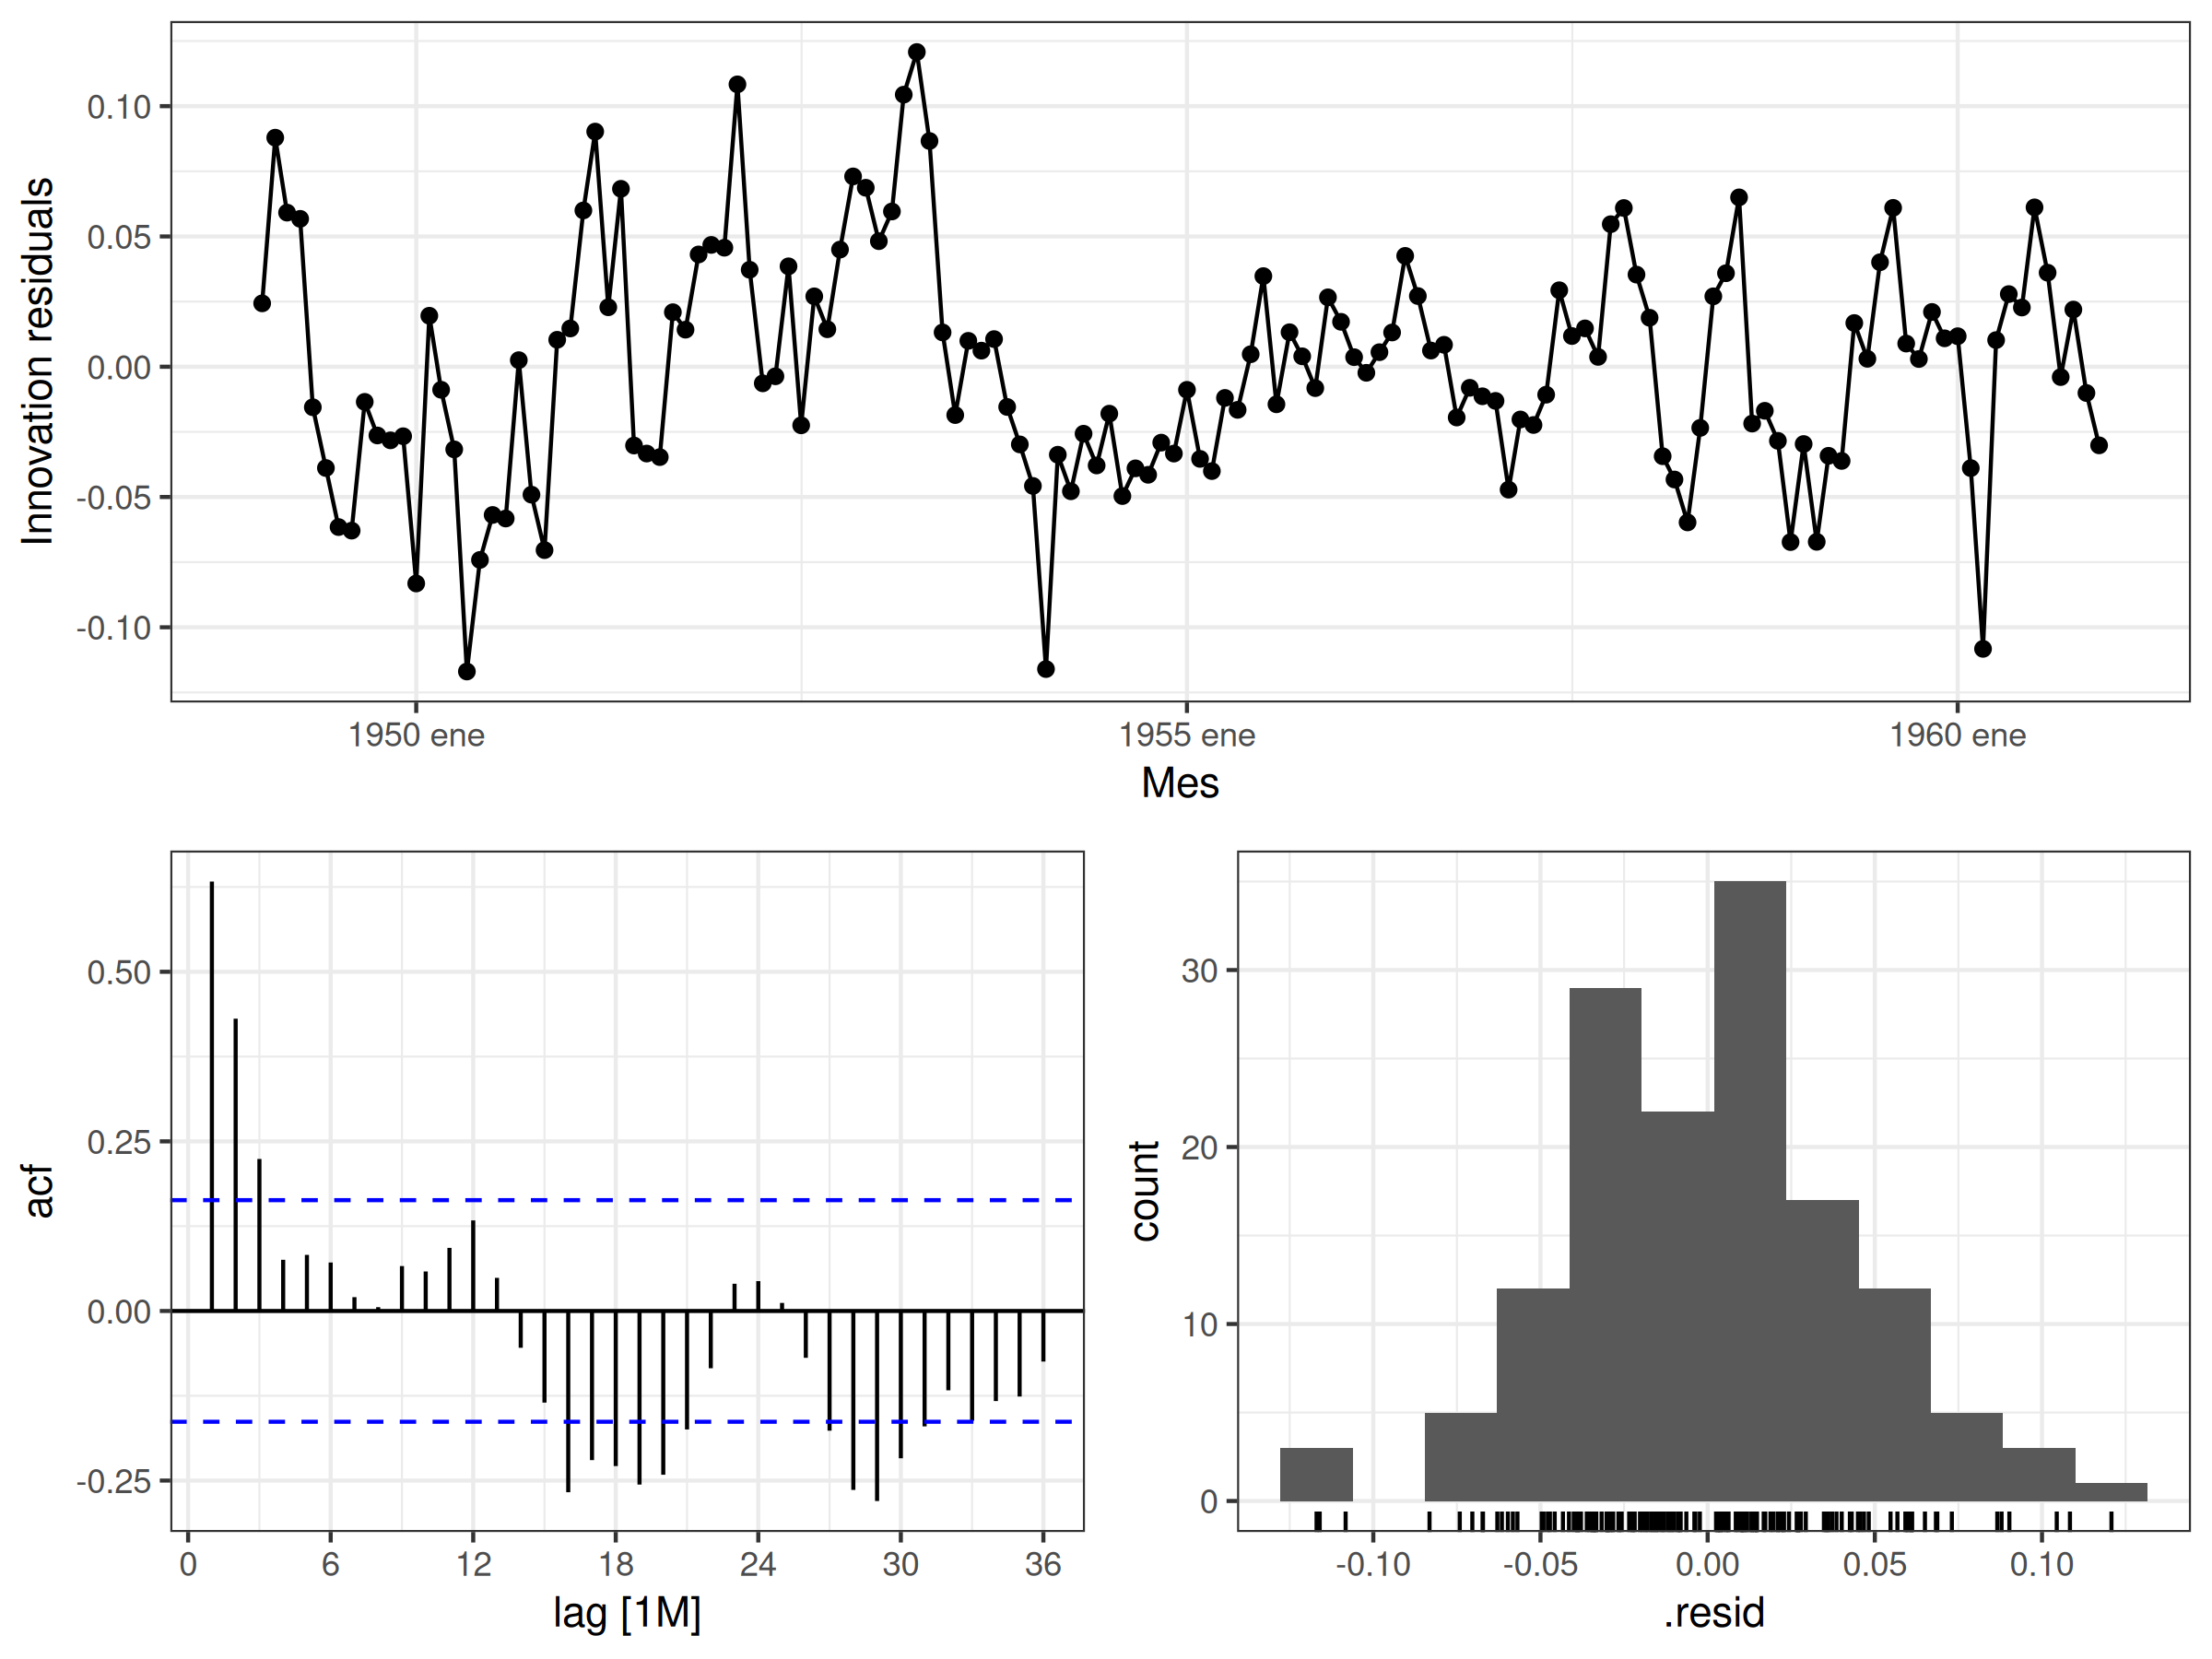

In [5]:
# Diagnóstico de los residuos
fit_itr_mco |> gg_tsresiduals(lag_max = 36)

augment(fit_itr_mco) |>
  features(.innov, ljung_box, lag = 24)

**Interpretación**

- El modelo estima un cambio de nivel $\beta_2 = -0.439$, que equivale a una caída de $100\,(e^{-0.439} - 1) = -35.5\%$, y un cambio de pendiente negativo y significativo.
- Los residuos están claramente autocorrelacionados. El ACF tiene muchas barras fuera de las bandas y la prueba de Ljung-Box rechaza que sean ruido blanco. Con autocorrelación los errores estándar de MCO no son confiables, por lo que las pruebas de significancia tampoco lo son.
- Los residuos también muestran ondas largas en el tiempo. Esto indica que una tendencia lineal en el logaritmo no describe bien la serie, porque el crecimiento de los pasajeros se desacelera al final del periodo.

### Modelo ITR con errores estándar de Newey-West

- El estimador de Newey-West corrige los errores estándar por autocorrelación y heterocedasticidad sin cambiar los coeficientes estimados por mínimos cuadrados. Para usarlo estimamos el mismo modelo con `lm()`.
- El parámetro `lag` es el número máximo de rezagos en los que se supone que hay autocorrelación. Con datos mensuales usamos 12.

In [6]:
modelo_lm <- lm(log(Pasajeros) ~ t + factor(month(Mes)) + D + t_post, data = pasajeros)

# Errores estándar de MCO y de Newey-West para las variables de la intervención
coef_mco <- coeftest(modelo_lm)
coef_nw  <- coeftest(modelo_lm, vcov = NeweyWest(modelo_lm, lag = 12, prewhite = FALSE))

variables <- c("t", "D", "t_post")
tibble(
  Variable          = variables,
  Coeficiente       = coef_mco[variables, "Estimate"],
  `Error est. MCO`  = coef_mco[variables, "Std. Error"],
  `Error est. NW`   = coef_nw[variables, "Std. Error"],
  `p-valor MCO`     = coef_mco[variables, "Pr(>|t|)"],
  `p-valor NW`      = coef_nw[variables, "Pr(>|t|)"]
) |>
  mutate(across(where(is.numeric), \(x) round(x, 4)))

Variable,Coeficiente,Error est. MCO,Error est. NW,p-valor MCO,p-valor NW
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
t,0.0112,0.0001,0.0002,0e+00,0e+00
D,-0.4391,0.0171,0.0187,0e+00,0e+00
t_post,-0.0024,0.0007,0.0006,6e-04,1e-04


**Interpretación**

- Los coeficientes son los mismos de MCO, porque Newey-West solo corrige los errores estándar. En este caso los errores estándar cambian poco y las tres variables siguen siendo significativas.
- Newey-West no corrige el sesgo de los coeficientes. Como la tendencia lineal no describe bien la serie, el modelo sobreestima la caída del nivel (−35.5% frente al −30% verdadero) y encuentra un cambio de pendiente que en realidad no existe.

### Modelo ITR con errores ARIMA

- La otra forma de tratar la autocorrelación es modelar el error $\eta_t$ con un proceso ARIMA. Es la regresión con errores ARIMA de Hyndman y Athanasopoulos (2021, capítulo 10).

$$
\log(Y_t) = \beta_2 D_t + \beta_3 \left[t - T_I \right] D_t + \eta_t, \qquad \eta_t \sim ARIMA(p,d,q)(P,1,Q)_{12}
$$

- `ARIMA()` elige automáticamente el orden del error. Con `PDQ(D = 1)` pedimos una diferencia estacional, de modo que la estacionalidad queda en el error y no se agrega `season()`.

In [7]:
fit_itr_arima <- pasajeros |>
  model(itr_arima = ARIMA(log(Pasajeros) ~ D + t_post + PDQ(D = 1)))

report(fit_itr_arima)

Series: Pasajeros 
Model: LM w/ ARIMA(0,1,1)(0,1,1)[12] errors 
Transformation: log(Pasajeros) 

Coefficients:
         ma1     sma1        D   t_post
      -0.416  -0.5581  -0.3810  -0.0049
s.e.   0.092   0.0728   0.0296   0.0053

sigma^2 estimated as 0.001378:  log likelihood=245.39
AIC=-480.79   AICc=-480.31   BIC=-466.41


.model,lb_stat,lb_pvalue
<chr>,<dbl>,<dbl>
itr_arima,27.35655,0.1979961


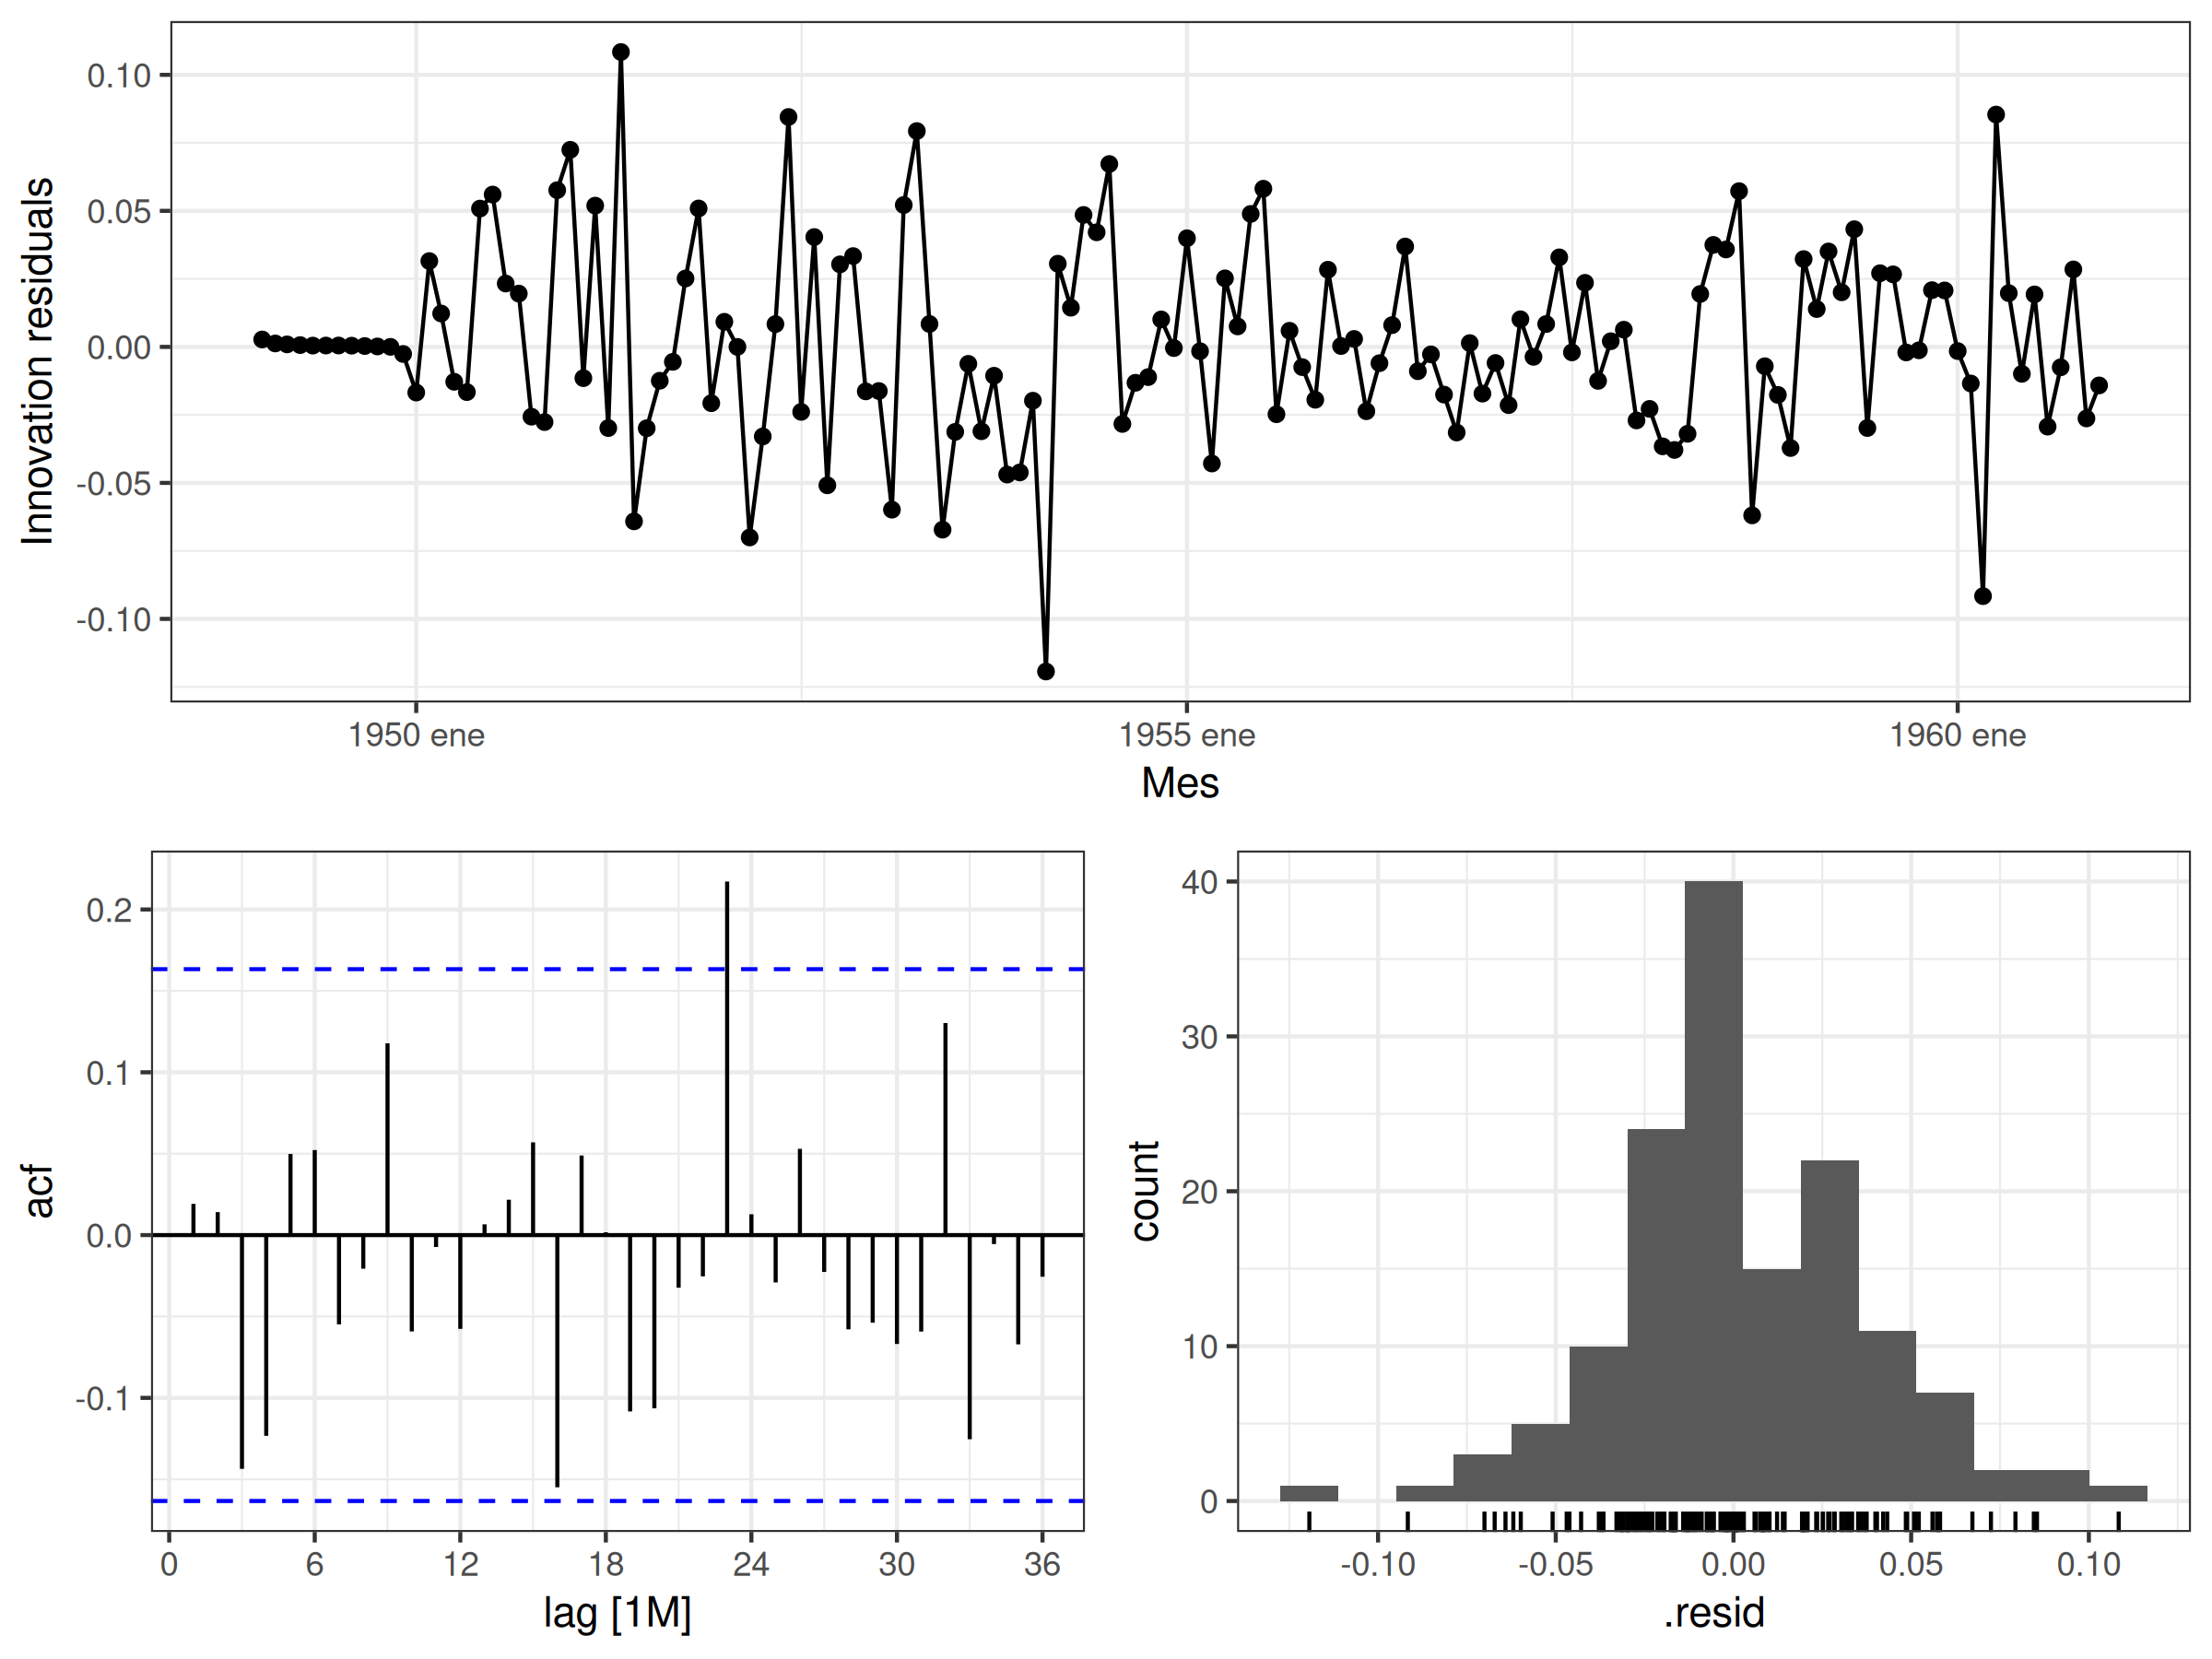

In [8]:
fit_itr_arima |> gg_tsresiduals(lag_max = 36)

augment(fit_itr_arima) |>
  features(.innov, ljung_box, lag = 24, dof = nrow(tidy(fit_itr_arima)) - 2)

In [9]:
# Efecto estimado de la intervención en cada modelo
bind_rows(
  tidy(fit_itr_mco),
  tidy(fit_itr_arima)
) |>
  filter(term %in% c("D", "t_post")) |>
  transmute(
    Modelo         = .model,
    Variable       = term,
    Coeficiente    = round(estimate, 4),
    `Error est.`   = round(std.error, 4),
    `p-valor`      = round(p.value, 4),
    `Efecto en nivel (%)` = if_else(term == "D", round(100 * (exp(estimate) - 1), 2), NA)
  )

Modelo,Variable,Coeficiente,Error est.,p-valor,Efecto en nivel (%)
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
itr_mco,D,-0.4391,0.0171,0.0000,-35.54
itr_mco,t_post,-0.0024,0.0007,0.0006,NA
itr_arima,D,-0.3810,0.0296,0.0000,-31.68
itr_arima,t_post,-0.0049,0.0053,0.3563,NA


**Interpretación**

- Con errores ARIMA, la búsqueda automática elige el modelo $ARIMA(0,1,1)(0,1,1)_{12}$ para $\eta_t$, conocido como modelo de aerolínea. Como el error tiene una diferencia regular y una estacional, la tendencia $t$ desaparece al diferenciar y por eso no se incluye en la fórmula.
- Los residuos de este modelo se comportan como ruido blanco, porque la prueba de Ljung-Box no rechaza su hipótesis nula.
- El efecto estimado es una caída de cerca del 32%, muy cerca del 30% verdadero, y el cambio de pendiente no es significativo, lo que coincide con la intervención simulada.
- Este ejemplo muestra que el modelo ITR por MCO puede llevar a conclusiones equivocadas cuando la tendencia está mal especificada y los errores están autocorrelacionados. El modelo con errores ARIMA recupera mejor el efecto verdadero.

### Contrafactual pronosticado

- Otra forma de medir el efecto es construir un **contrafactual**, es decir, estimar qué habría pasado sin la intervención. Ajustamos un modelo solo con los datos anteriores a la intervención y lo usamos para pronosticar el periodo posterior. Esta es la idea de los modelos de espacio de estados bayesianos que vimos en la presentación (CausalImpact).
- El efecto puntual es la diferencia entre lo observado y el contrafactual, $\tau_t = y_t - \hat{y}_t(0)$, y el efecto acumulado es la suma de los efectos puntuales.

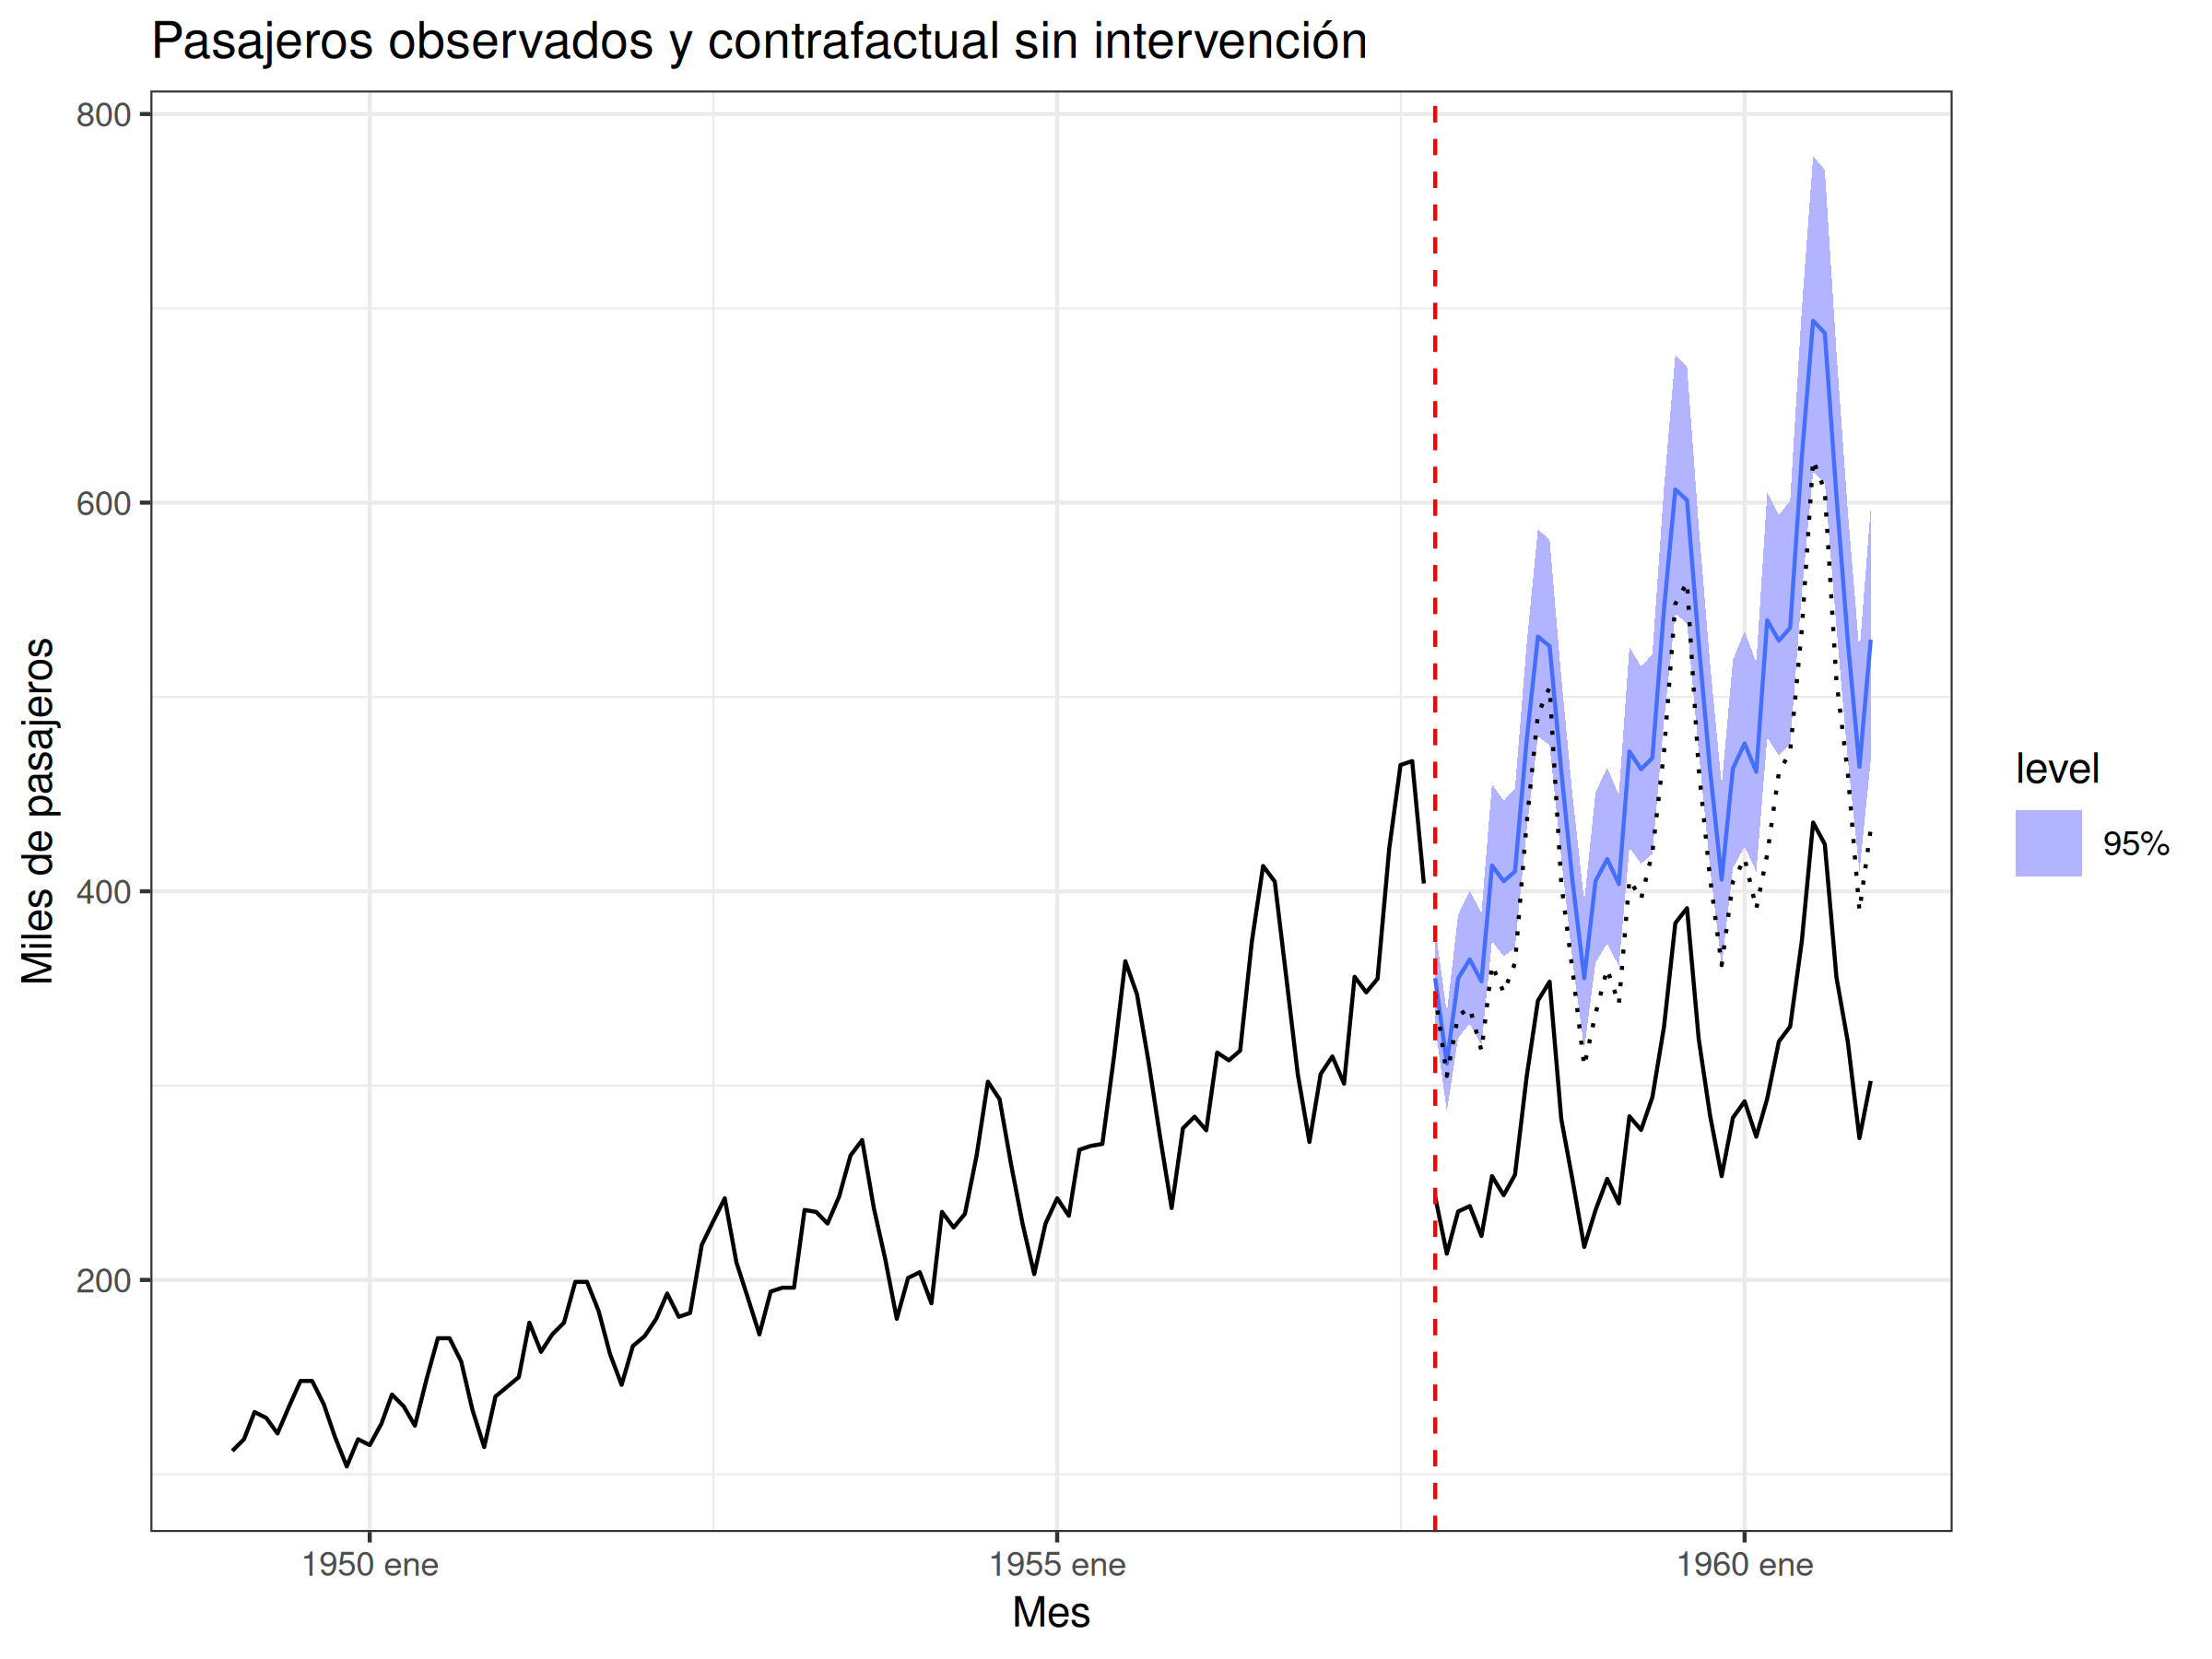

In [10]:
antes   <- pasajeros |> filter(Mes < fecha_intervencion)
despues <- pasajeros |> filter(Mes >= fecha_intervencion)

contrafactual <- antes |>
  model(ARIMA(log(Pasajeros))) |>
  forecast(h = nrow(despues))

# Serie original sin intervención, que en este ejemplo es el contrafactual verdadero
original <- read_csv("../data/AirPassengers.csv", show_col_types = FALSE) |>
  mutate(Mes = yearmonth(ds)) |>
  select(Mes, Original = y) |>
  filter(Mes >= fecha_intervencion)

contrafactual |>
  autoplot(antes, level = 95) +
  geom_line(data = despues, aes(x = Mes, y = Pasajeros), colour = "black") +
  geom_line(data = original, aes(x = Mes, y = Original), colour = "black", linetype = "dotted") +
  geom_vline(xintercept = as.Date(fecha_intervencion), linetype = "dashed", colour = "red") +
  labs(title = "Pasajeros observados y contrafactual sin intervención",
       x = "Mes", y = "Miles de pasajeros")

In [11]:
efecto <- despues |>
  as_tibble() |>
  select(Mes, Observado = Pasajeros) |>
  left_join(as_tibble(contrafactual) |> select(Mes, Contrafactual = .mean), by = "Mes") |>
  left_join(original, by = "Mes") |>
  mutate(Efecto_puntual = Observado - Contrafactual)

efecto |>
  summarise(
    `Efecto acumulado (miles)`          = sum(Efecto_puntual),
    `Efecto relativo estimado (%)`      = 100 * (sum(Observado) / sum(Contrafactual) - 1),
    `Efecto relativo verdadero (%)`     = 100 * (sum(Observado) / sum(Original) - 1)
  ) |>
  mutate(across(everything(), \(x) round(x, 2)))

Efecto acumulado (miles),Efecto relativo estimado (%),Efecto relativo verdadero (%)
<dbl>,<dbl>,<dbl>
-7150.85,-38.36,-30


**Interpretación**

- El contrafactual pronosticado estima una caída de los pasajeros cercana al 38%, mayor que el 30% verdadero.
- Como en este ejemplo conocemos la serie original sin intervención (línea punteada), podemos ver la causa. El modelo estimado hasta septiembre de 1957 proyecta el crecimiento de los años anteriores, pero en 1958 los pasajeros crecieron mucho menos. El contrafactual queda por encima de lo que realmente habría pasado y el efecto se sobreestima.
- La calidad de este método depende de la calidad del pronóstico del contrafactual. Por eso los modelos como CausalImpact usan series de control que no recibieron la intervención para mejorar ese pronóstico.

## Ejemplo 2. Efecto de la pandemia del COVID-19 en el desempleo de Colombia

- La cuarentena nacional empezó a finales de marzo de 2020. Usamos la tasa de desempleo mensual del DANE y construimos el contrafactual con un modelo ARIMA estimado hasta febrero de 2020.
- En este caso no conocemos el efecto verdadero. Además, en el periodo posterior ocurrieron otros hechos que afectan el empleo, por lo que el efecto estimado debe interpretarse con cuidado. Este es el problema de **historia** que mencionamos en la presentación.

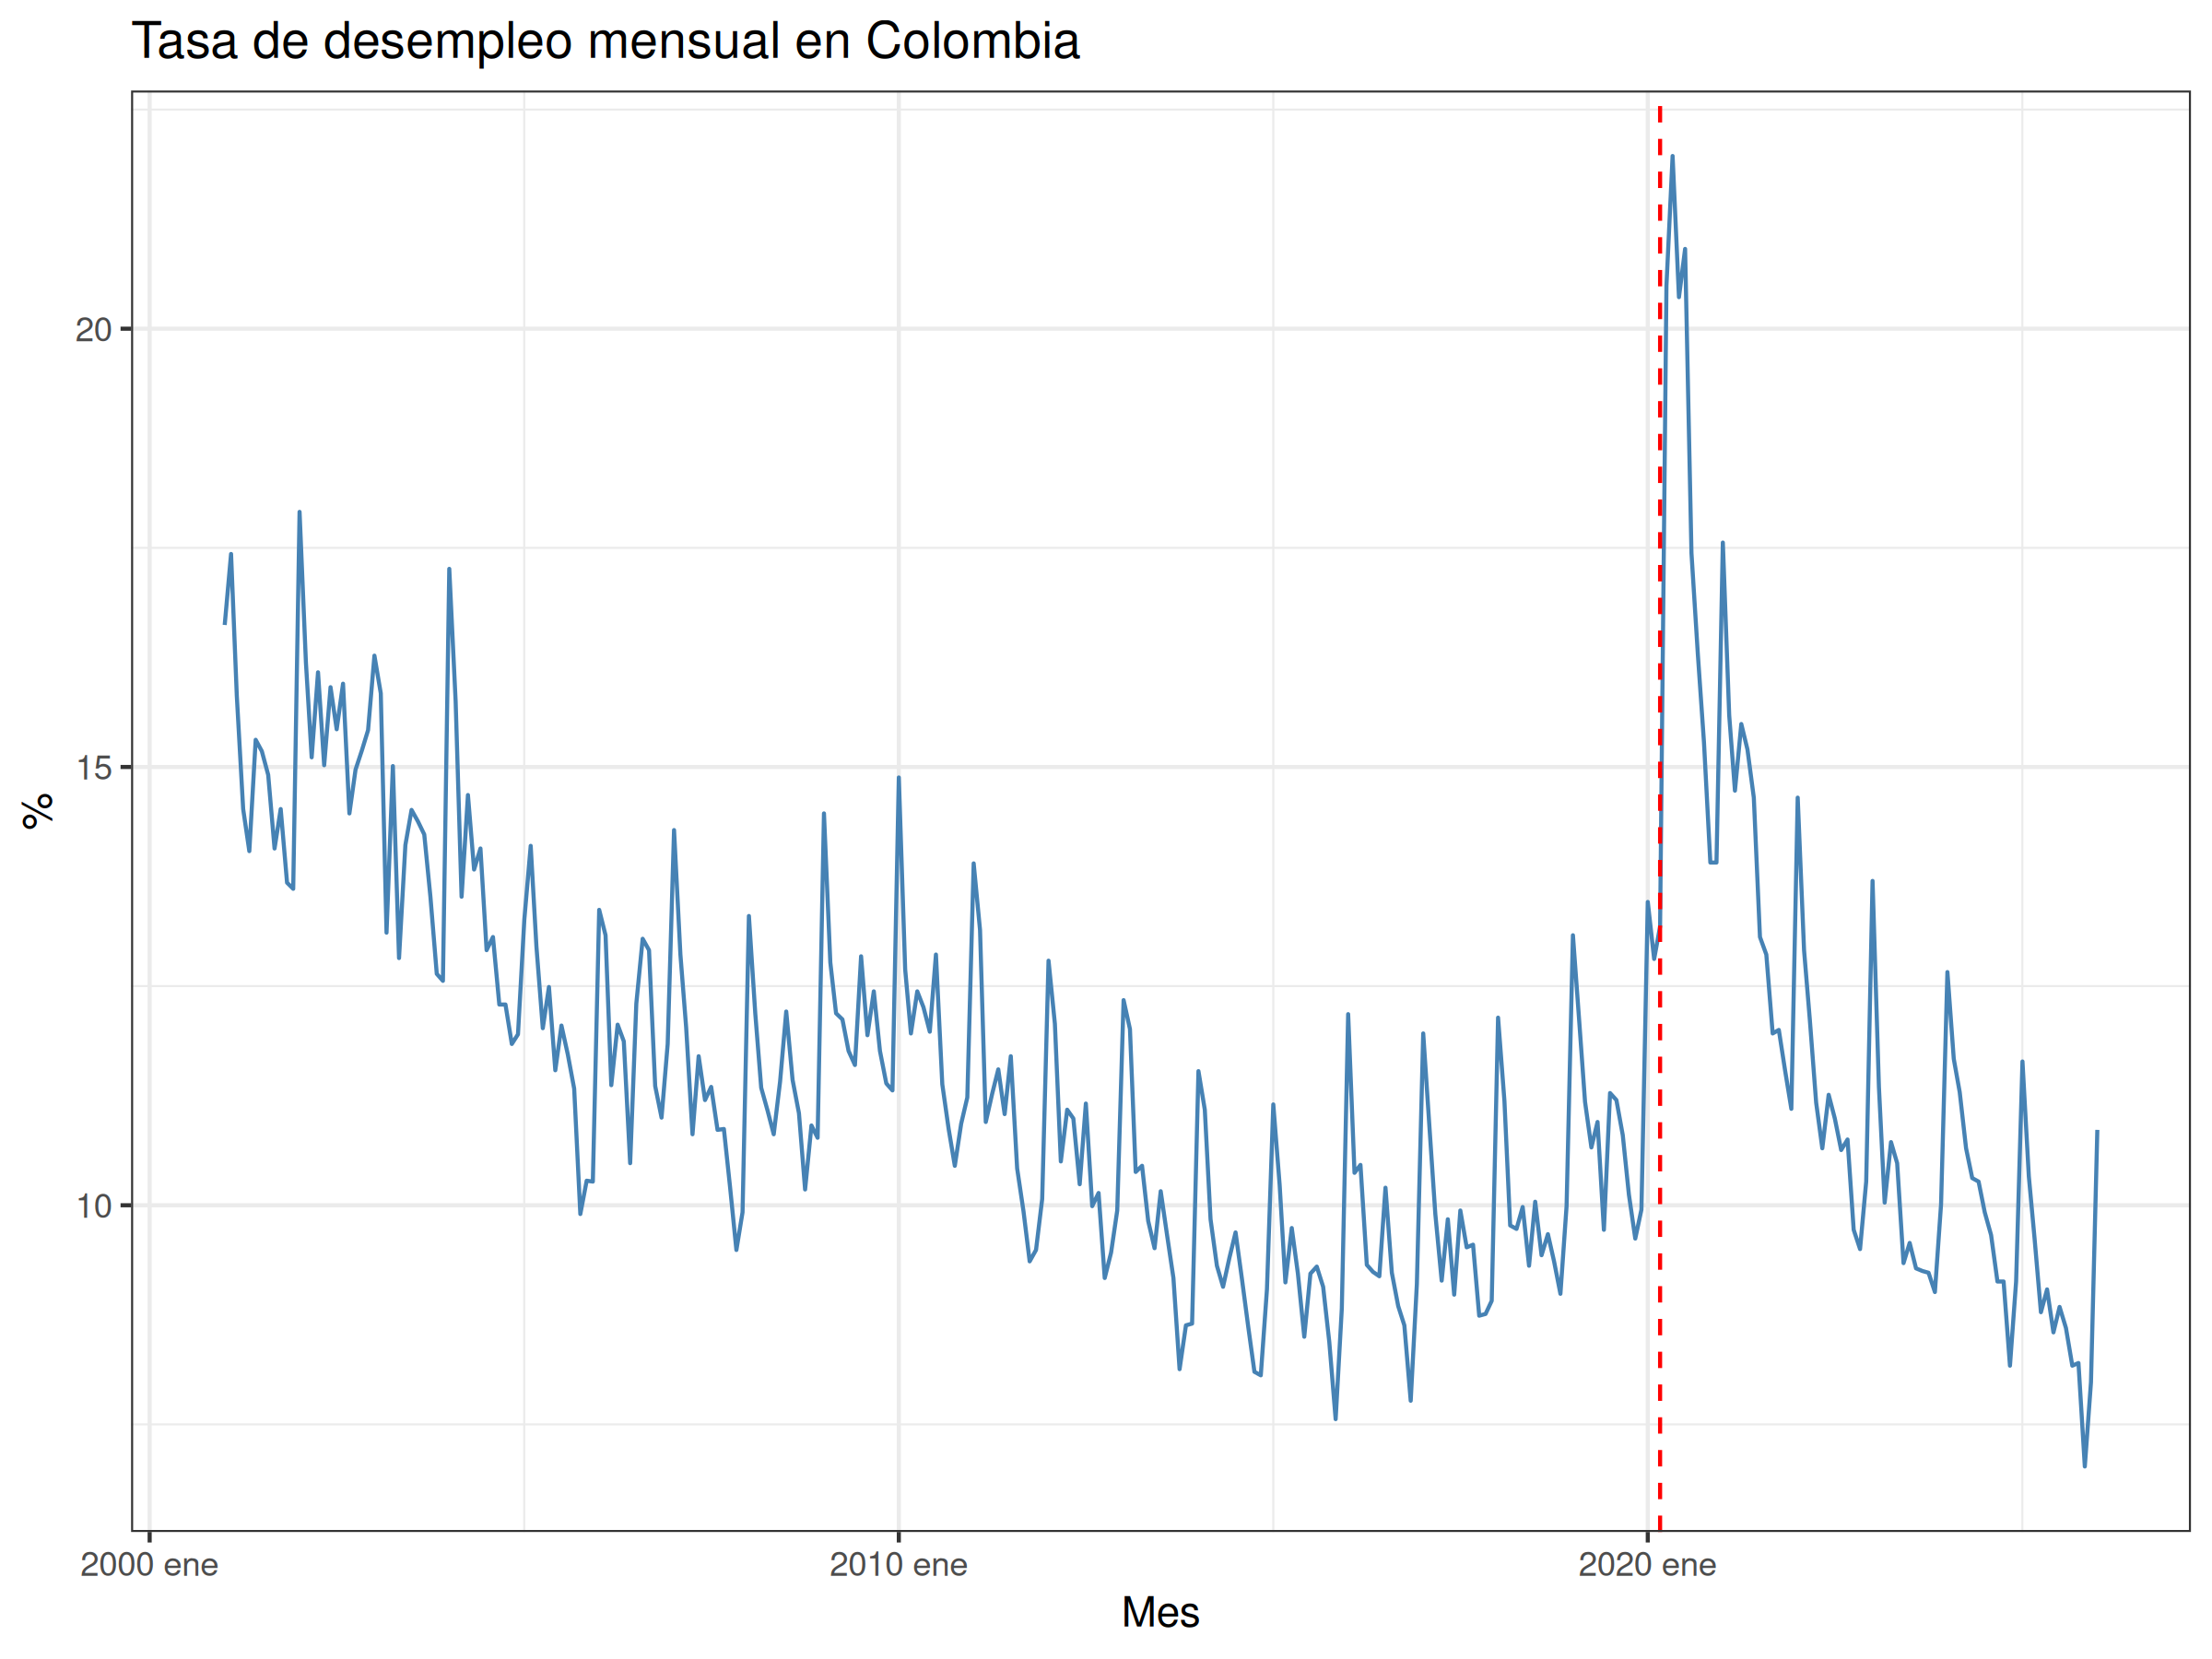

In [12]:
desempleo <- read_delim("../data/mercado_laboral_colombia_impact.csv", delim = ";",
                        locale = locale(decimal_mark = ","), show_col_types = FALSE) |>
  select(fecha = 1, Desempleo = 2) |>
  mutate(Mes = yearmonth(ymd(fecha))) |>
  select(Mes, Desempleo) |>
  as_tsibble(index = Mes)

fecha_covid <- yearmonth("2020 Mar")

desempleo |>
  autoplot(Desempleo, colour = "steelblue") +
  geom_vline(xintercept = as.Date(fecha_covid), linetype = "dashed", colour = "red") +
  labs(title = "Tasa de desempleo mensual en Colombia", x = "Mes", y = "%")

Series: Desempleo 
Model: ARIMA(1,1,2)(2,1,0)[12] 

Coefficients:
         ar1      ma1     ma2     sar1     sar2
      0.5318  -1.2095  0.4180  -0.7261  -0.2803
s.e.  0.2743   0.2635  0.1699   0.0690   0.0745

sigma^2 estimated as 0.3961:  log likelihood=-208.47
AIC=428.94   AICc=429.34   BIC=449.22


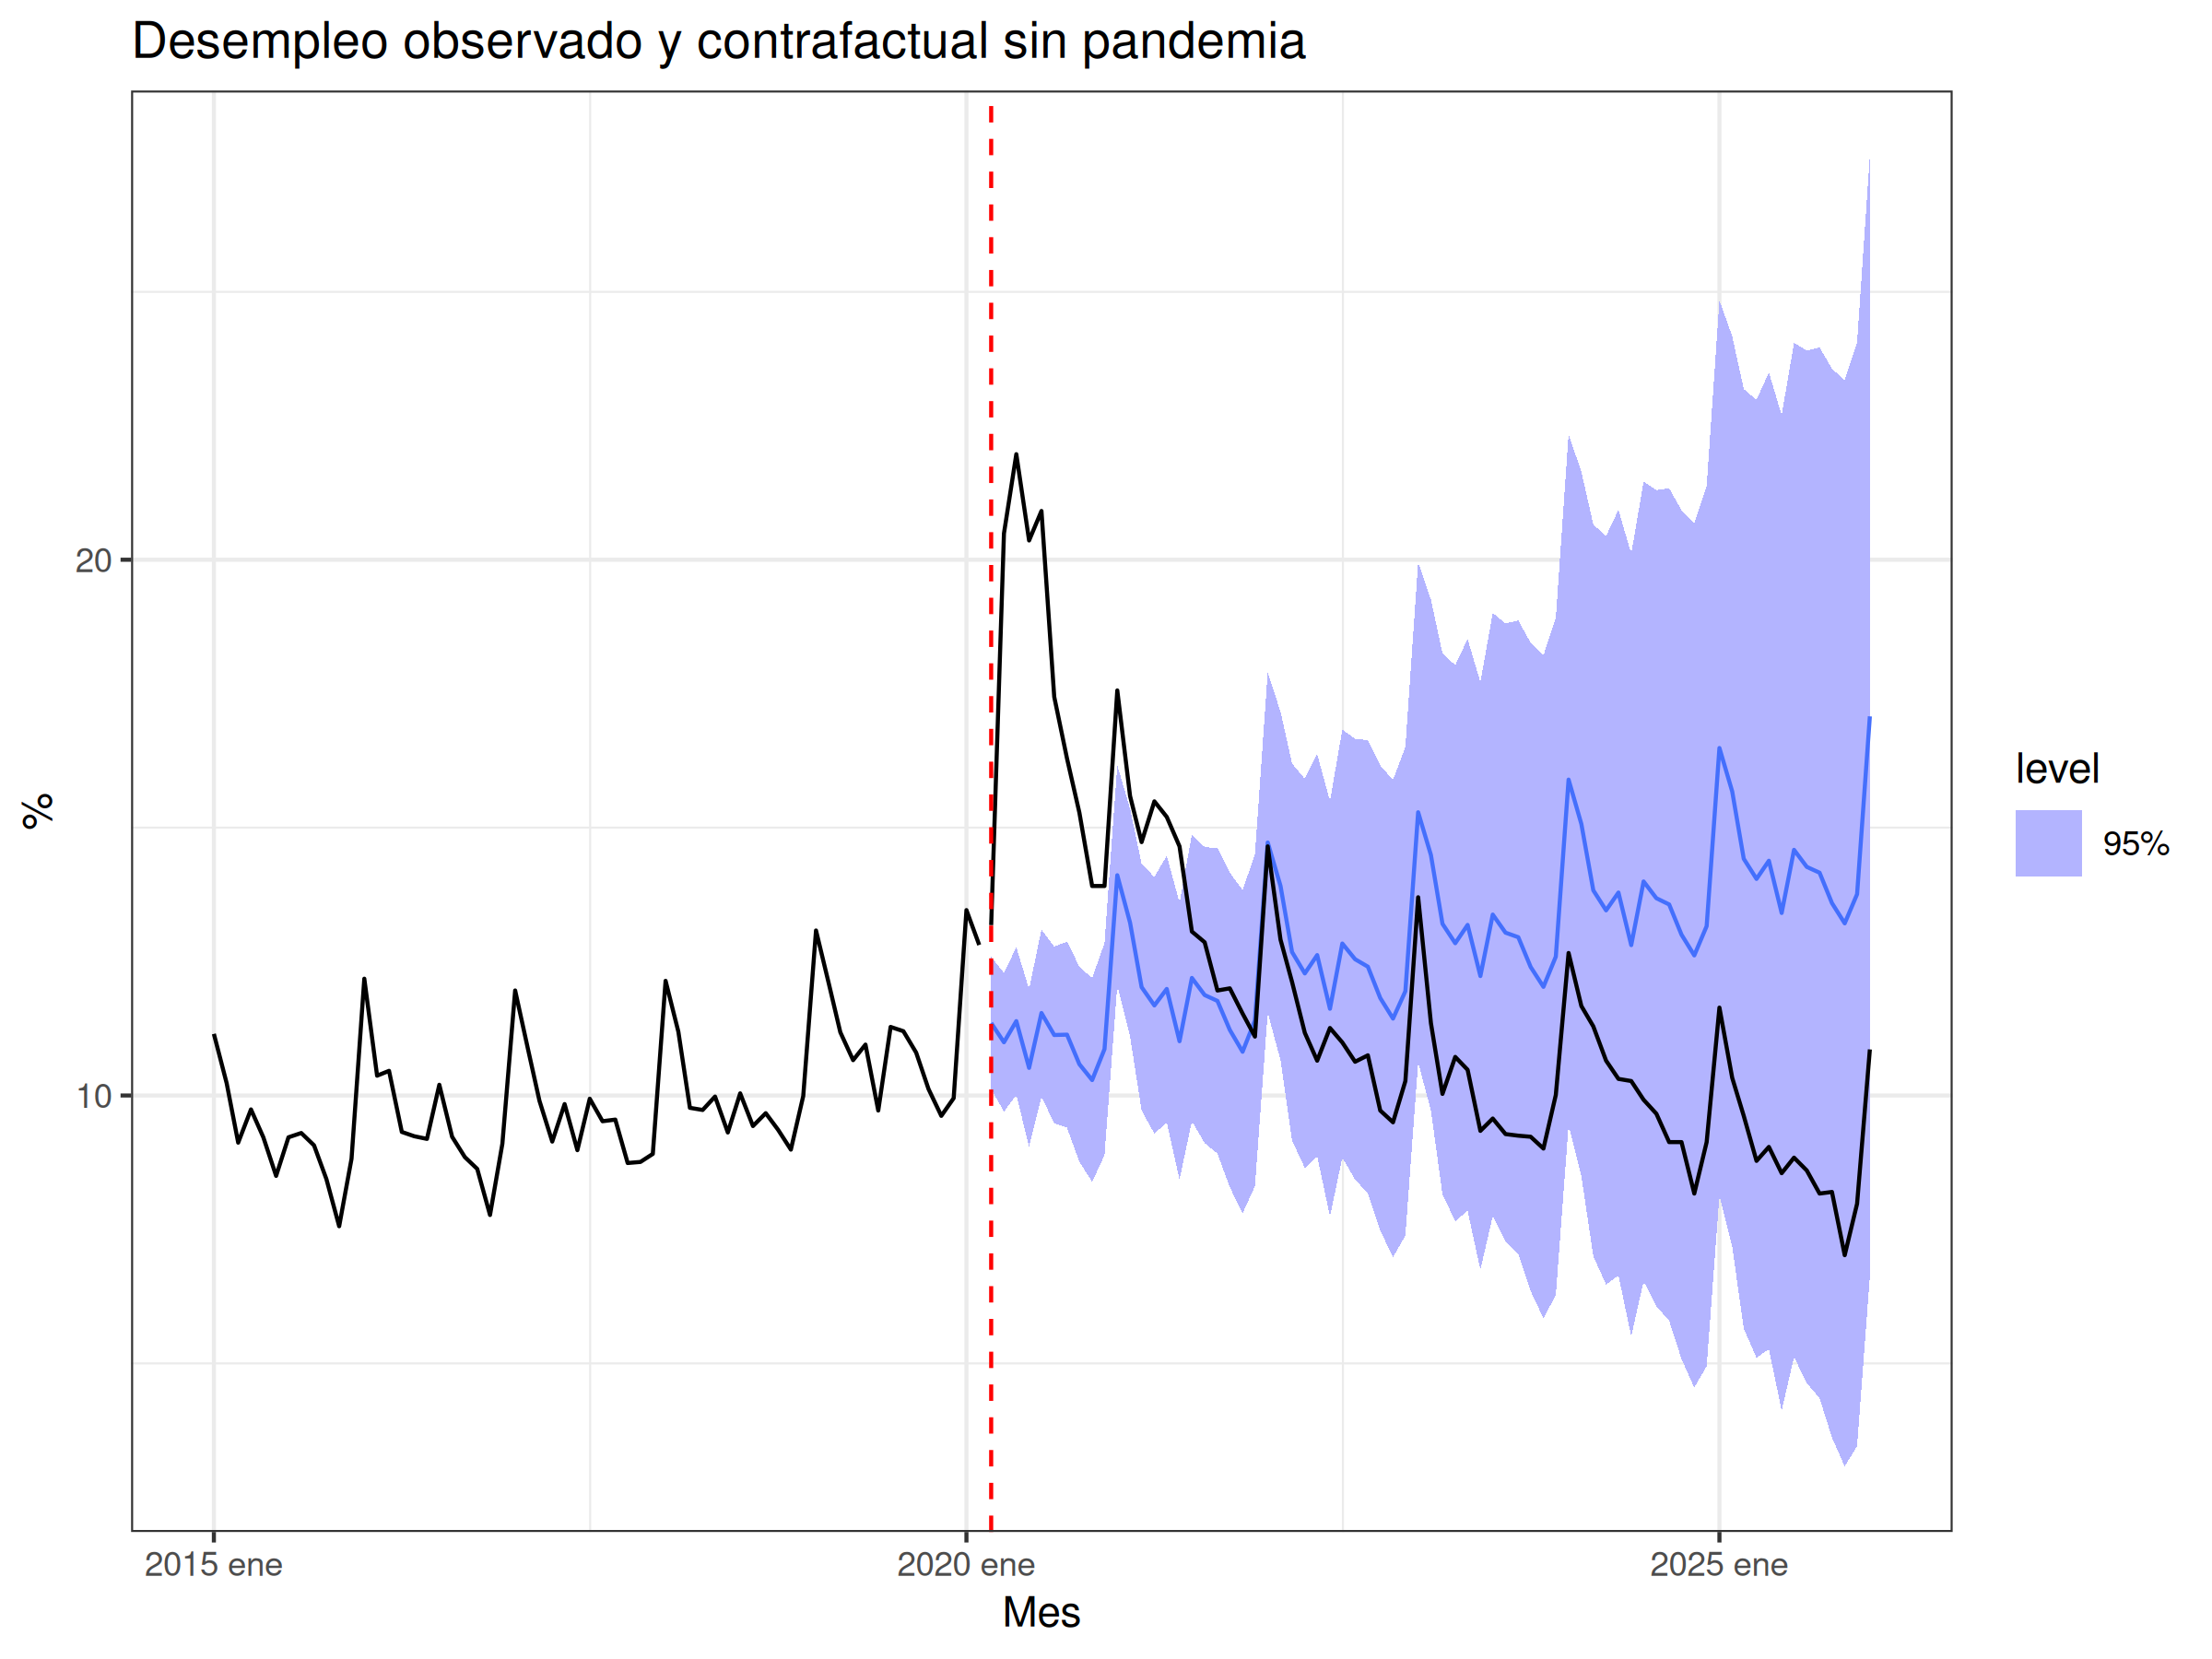

In [13]:
antes_covid   <- desempleo |> filter(Mes < fecha_covid)
despues_covid <- desempleo |> filter(Mes >= fecha_covid)

fit_pre_covid <- antes_covid |> model(ARIMA(Desempleo))
report(fit_pre_covid)

contrafactual_covid <- fit_pre_covid |> forecast(h = nrow(despues_covid))

contrafactual_covid |>
  autoplot(antes_covid |> filter(year(Mes) >= 2015), level = 95) +
  geom_line(data = despues_covid, aes(x = Mes, y = Desempleo), colour = "black") +
  geom_vline(xintercept = as.Date(fecha_covid), linetype = "dashed", colour = "red") +
  labs(title = "Desempleo observado y contrafactual sin pandemia",
       x = "Mes", y = "%")

Año,Efecto promedio (p.p.),Meses con efecto positivo significativo,Meses con efecto negativo significativo
<dbl>,<dbl>,<int>,<int>
2020,6.39,10,0
2021,1.87,6,0
2022,-1.35,0,0
2023,-2.97,0,0
2024,-3.57,0,0
2025,-5.43,0,0
2026,-6.22,0,0


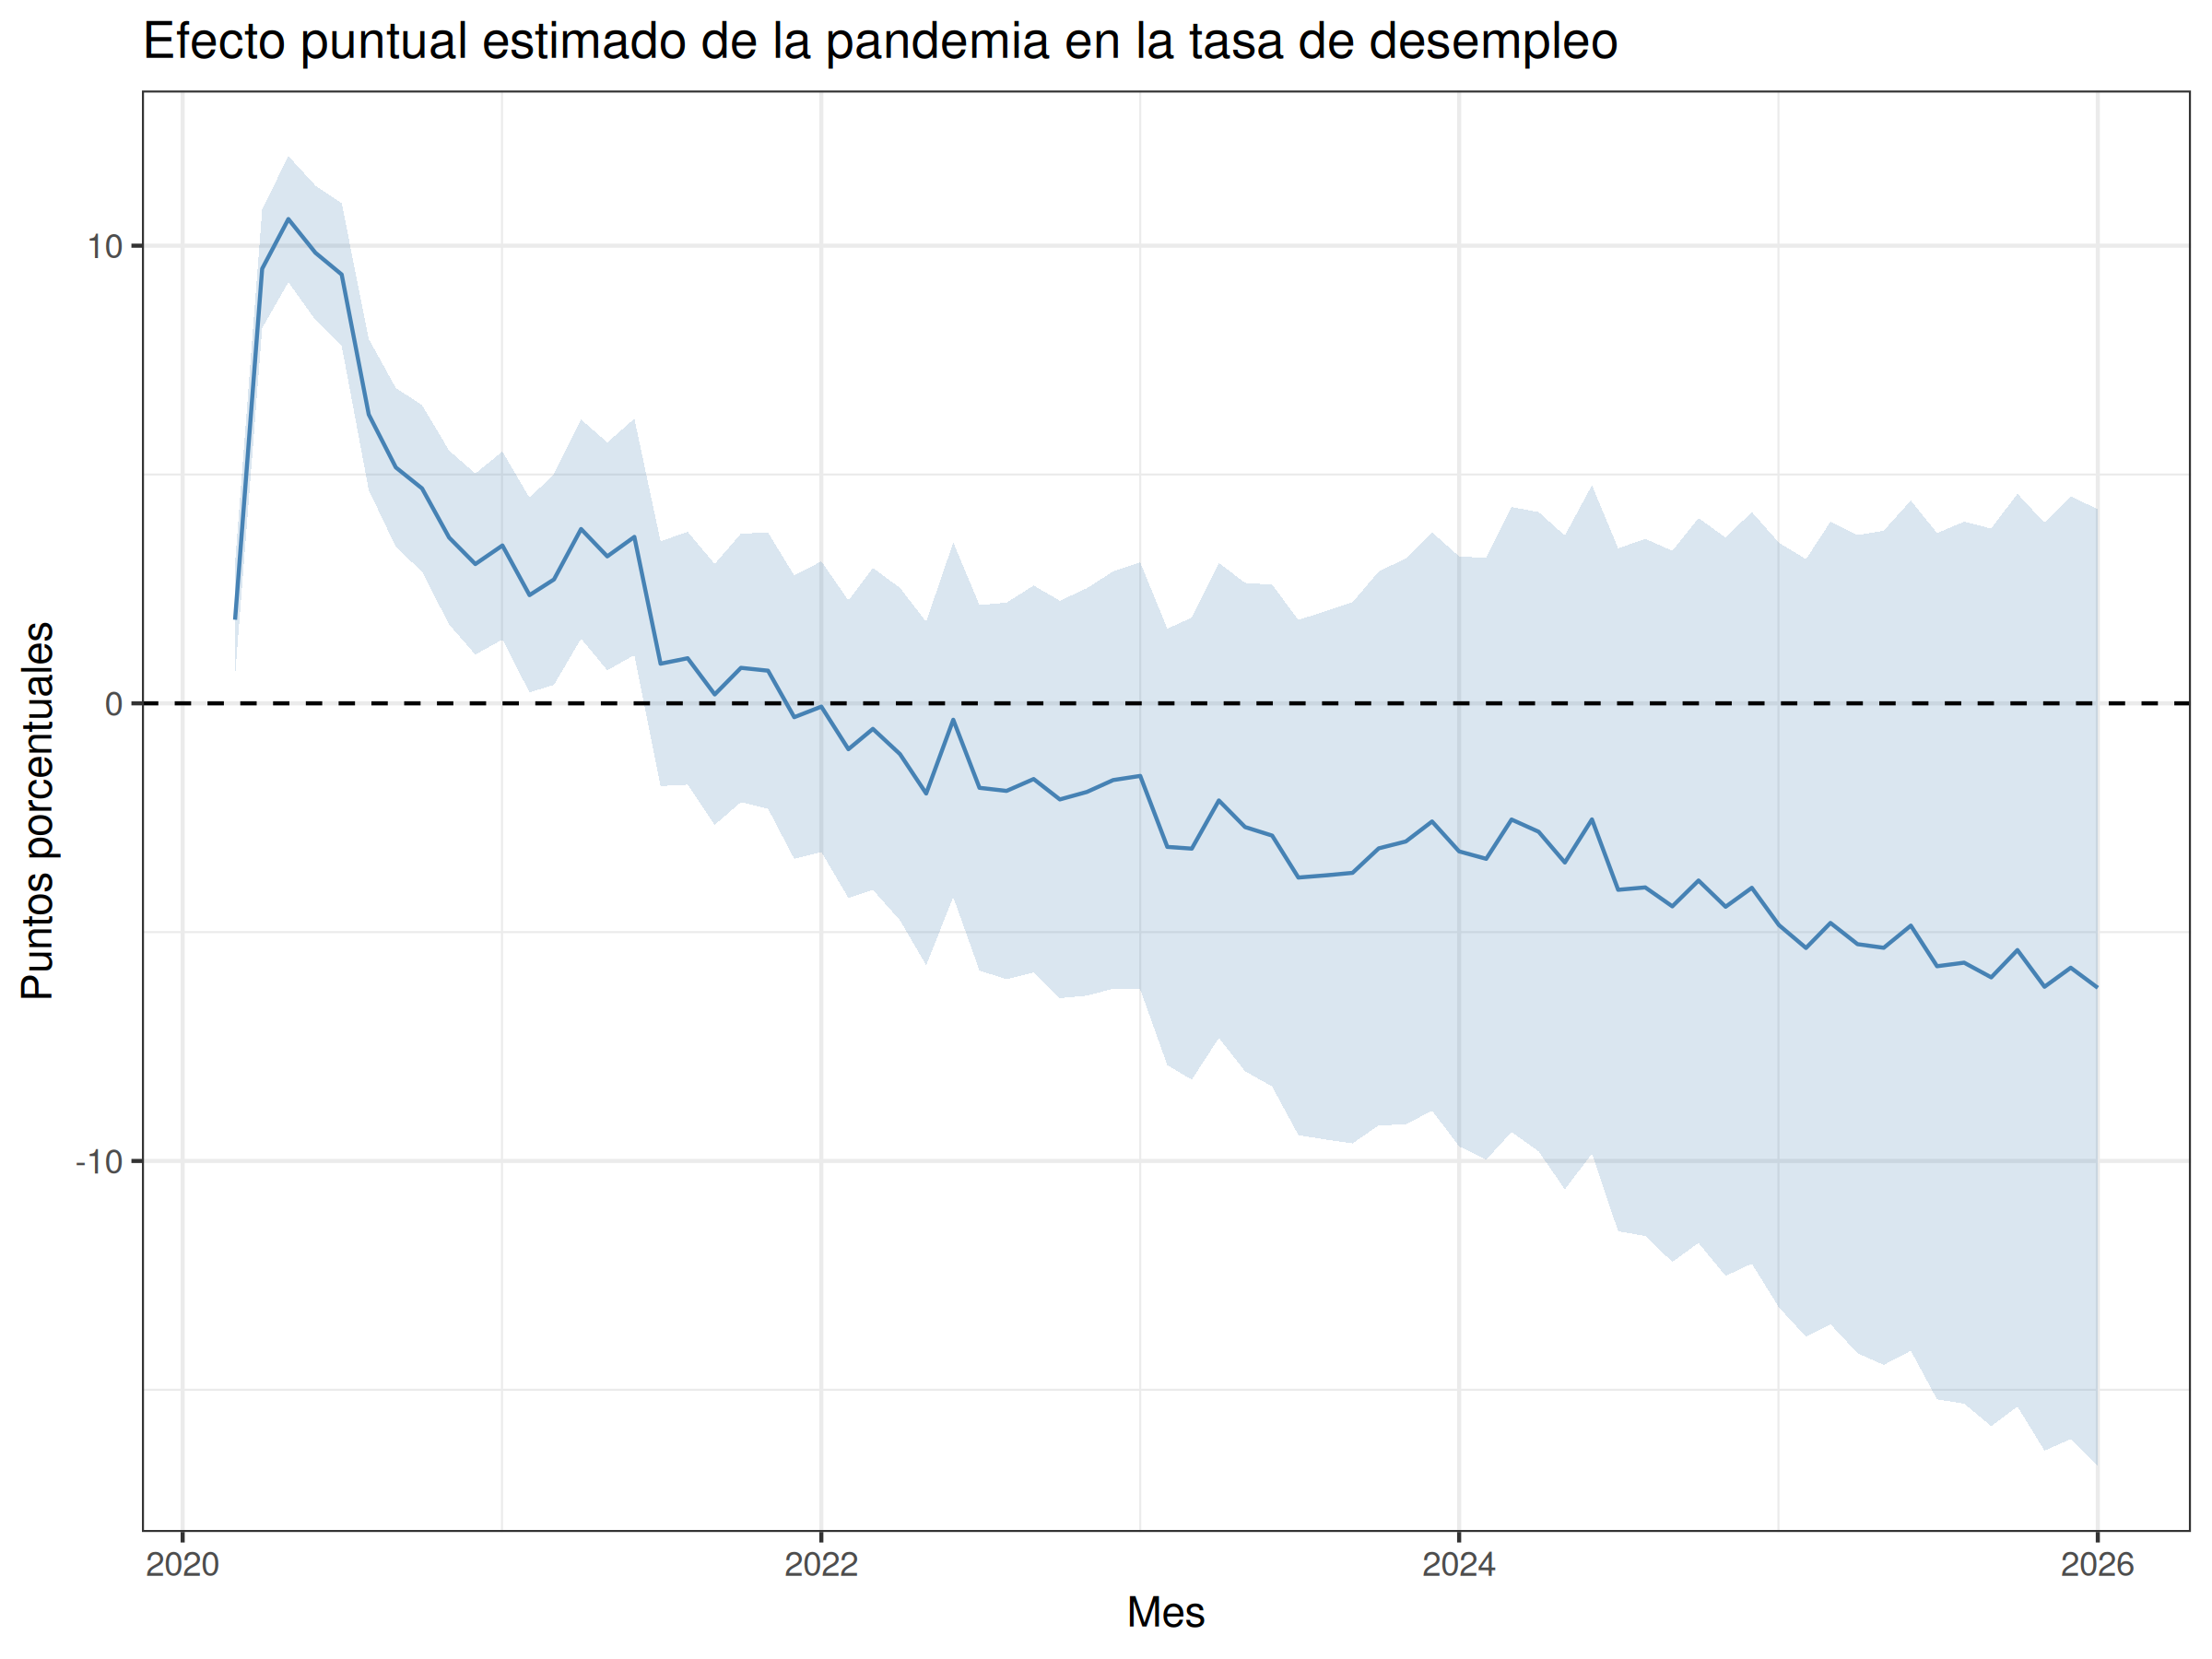

In [14]:
# Efecto puntual con su intervalo del 95%
efecto_covid <- contrafactual_covid |>
  hilo(level = 95) |>
  unpack_hilo(`95%`) |>
  as_tibble() |>
  select(Mes, Contrafactual = .mean, inferior = `95%_lower`, superior = `95%_upper`) |>
  left_join(as_tibble(despues_covid), by = "Mes") |>
  mutate(
    Efecto          = Desempleo - Contrafactual,
    Efecto_inferior = Desempleo - superior,
    Efecto_superior = Desempleo - inferior
  )

efecto_covid |>
  ggplot(aes(x = as.Date(Mes), y = Efecto)) +
  geom_ribbon(aes(ymin = Efecto_inferior, ymax = Efecto_superior), fill = "steelblue", alpha = 0.2) +
  geom_line(colour = "steelblue") +
  geom_hline(yintercept = 0, linetype = "dashed") +
  labs(title = "Efecto puntual estimado de la pandemia en la tasa de desempleo",
       x = "Mes", y = "Puntos porcentuales")

# Efecto promedio por año
efecto_covid |>
  group_by(Año = year(Mes)) |>
  summarise(`Efecto promedio (p.p.)` = round(mean(Efecto), 2),
            `Meses con efecto positivo significativo` = sum(Efecto_inferior > 0),
            `Meses con efecto negativo significativo` = sum(Efecto_superior < 0))

**Interpretación**

- Entre abril y agosto de 2020 la tasa de desempleo observada supera ampliamente el intervalo del contrafactual. En 2020 el efecto promedio estimado es de unos 6.4 puntos porcentuales y en 2021 de unos 1.9 puntos.
- Desde 2022 la tasa observada vuelve a quedar dentro del intervalo del contrafactual, por lo que no hay evidencia de un efecto de la pandemia. Los efectos puntuales negativos de esos años no son significativos.
- El intervalo del contrafactual se hace muy ancho a medida que aumenta el horizonte. Por eso este método es más útil para medir el efecto de corto plazo. A largo plazo, además, el contrafactual mezcla el efecto de la pandemia con otros cambios del mercado laboral.

## Ejemplo 3. Diferencias en diferencias con datos simulados

- Para el estimador de diferencias en diferencias (DiD) necesitamos un grupo tratado y un grupo de control. Simulamos 48 meses de dos grupos con tendencias paralelas. El grupo tratado recibe una intervención en el mes 25 con un **efecto verdadero de 8 unidades**.

$$
Y_{t} = \beta_0 + \beta_1 \text{Tratamiento} + \beta_2 \text{Post}_t + \beta_3 (\text{Tratamiento} \cdot \text{Post}_t) + \varepsilon_{t}
$$

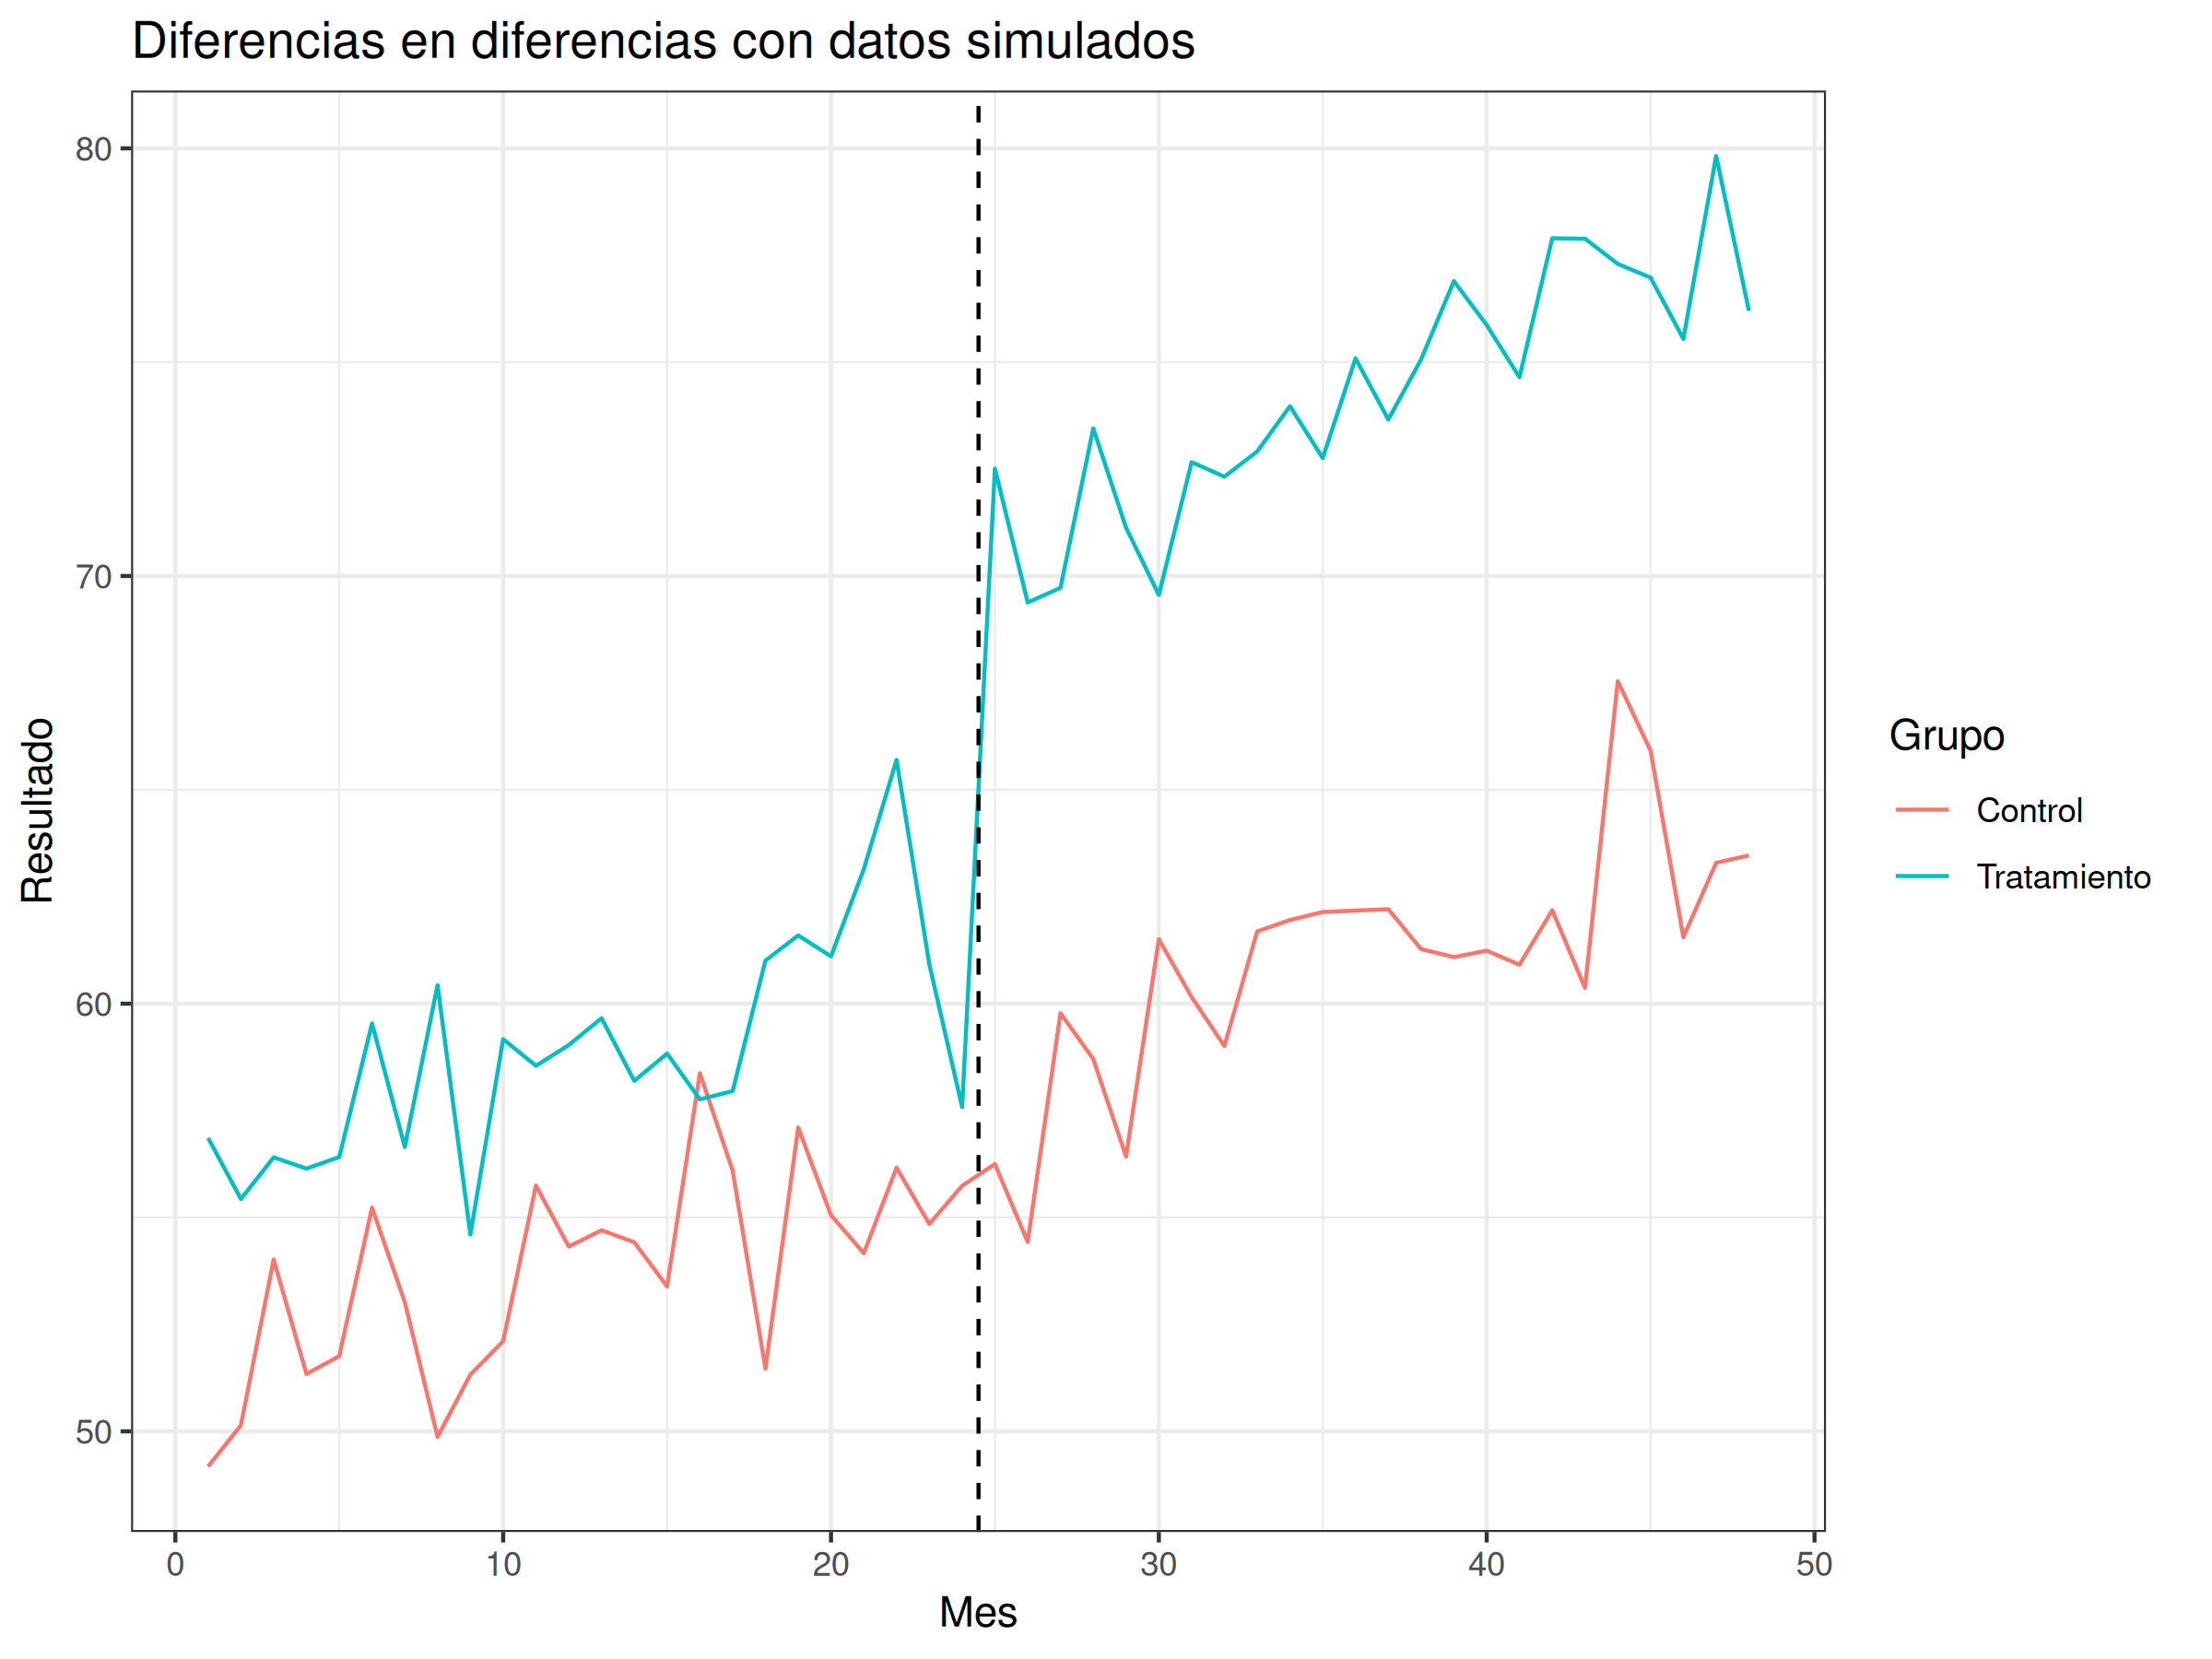

In [15]:
set.seed(123)

did <- expand_grid(Grupo = c("Control", "Tratamiento"), Mes = 1:48) |>
  mutate(
    Tratamiento = as.integer(Grupo == "Tratamiento"),
    Post        = as.integer(Mes >= 25),
    y           = 50 + 5 * Tratamiento + 0.3 * Mes + 8 * Tratamiento * Post + rnorm(n(), sd = 2)
  )

did |>
  ggplot(aes(Mes, y, colour = Grupo)) +
  geom_line() +
  geom_vline(xintercept = 24.5, linetype = "dashed") +
  labs(title = "Diferencias en diferencias con datos simulados", x = "Mes", y = "Resultado")

In [16]:
modelo_did <- lm(y ~ Tratamiento * Post, data = did)
coeftest(modelo_did, vcov = NeweyWest(modelo_did, lag = 3, prewhite = FALSE))


t test of coefficients:

                 Estimate Std. Error t value  Pr(>|t|)    
(Intercept)      53.73265    0.62342 86.1900 < 2.2e-16 ***
Tratamiento       5.12936    0.99322  5.1644 1.389e-06 ***
Post              7.32000    1.08767  6.7300 1.423e-09 ***
Tratamiento:Post  8.11925    1.62684  4.9908 2.834e-06 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


**Interpretación**

- El coeficiente de la interacción `Tratamiento:Post` es el estimador de diferencias en diferencias. Su valor es cercano a 8, el efecto verdadero de la simulación, y es significativo.
- El coeficiente de `Tratamiento` mide la diferencia de nivel entre los grupos antes de la intervención y el de `Post` mide el cambio del grupo de control entre los dos periodos.
- El método funciona porque los dos grupos tienen tendencias paralelas antes de la intervención. Si las tendencias fueran distintas, el estimador estaría sesgado.

# 2. Detección de valores atípicos

Al analizar series de tiempo distinguimos tres paradigmas de detección de anomalías. Los tiempos extraños son observaciones anómalas dentro de una serie histórica, las series extrañas son series anómalas dentro de un conjunto de series, y la vigilancia busca anomalías en tiempo real a medida que llegan nuevos datos.

## Ejemplo 4. Tiempos extraños en la tasa de desempleo de Colombia

- Seguimos el método de Hyndman y Athanasopoulos (2021, sección 13.9). Descomponemos la serie con STL robusto y analizamos el componente de residuo (*remainder*), que es lo que no explican la tendencia ni la estacionalidad.
- Una observación es atípica si su residuo está por debajo de $Q_1 - 3\,IQR$ o por encima de $Q_3 + 3\,IQR$, donde $Q_1$ y $Q_3$ son el primer y tercer cuartil del residuo e $IQR = Q_3 - Q_1$ es el rango intercuartílico.

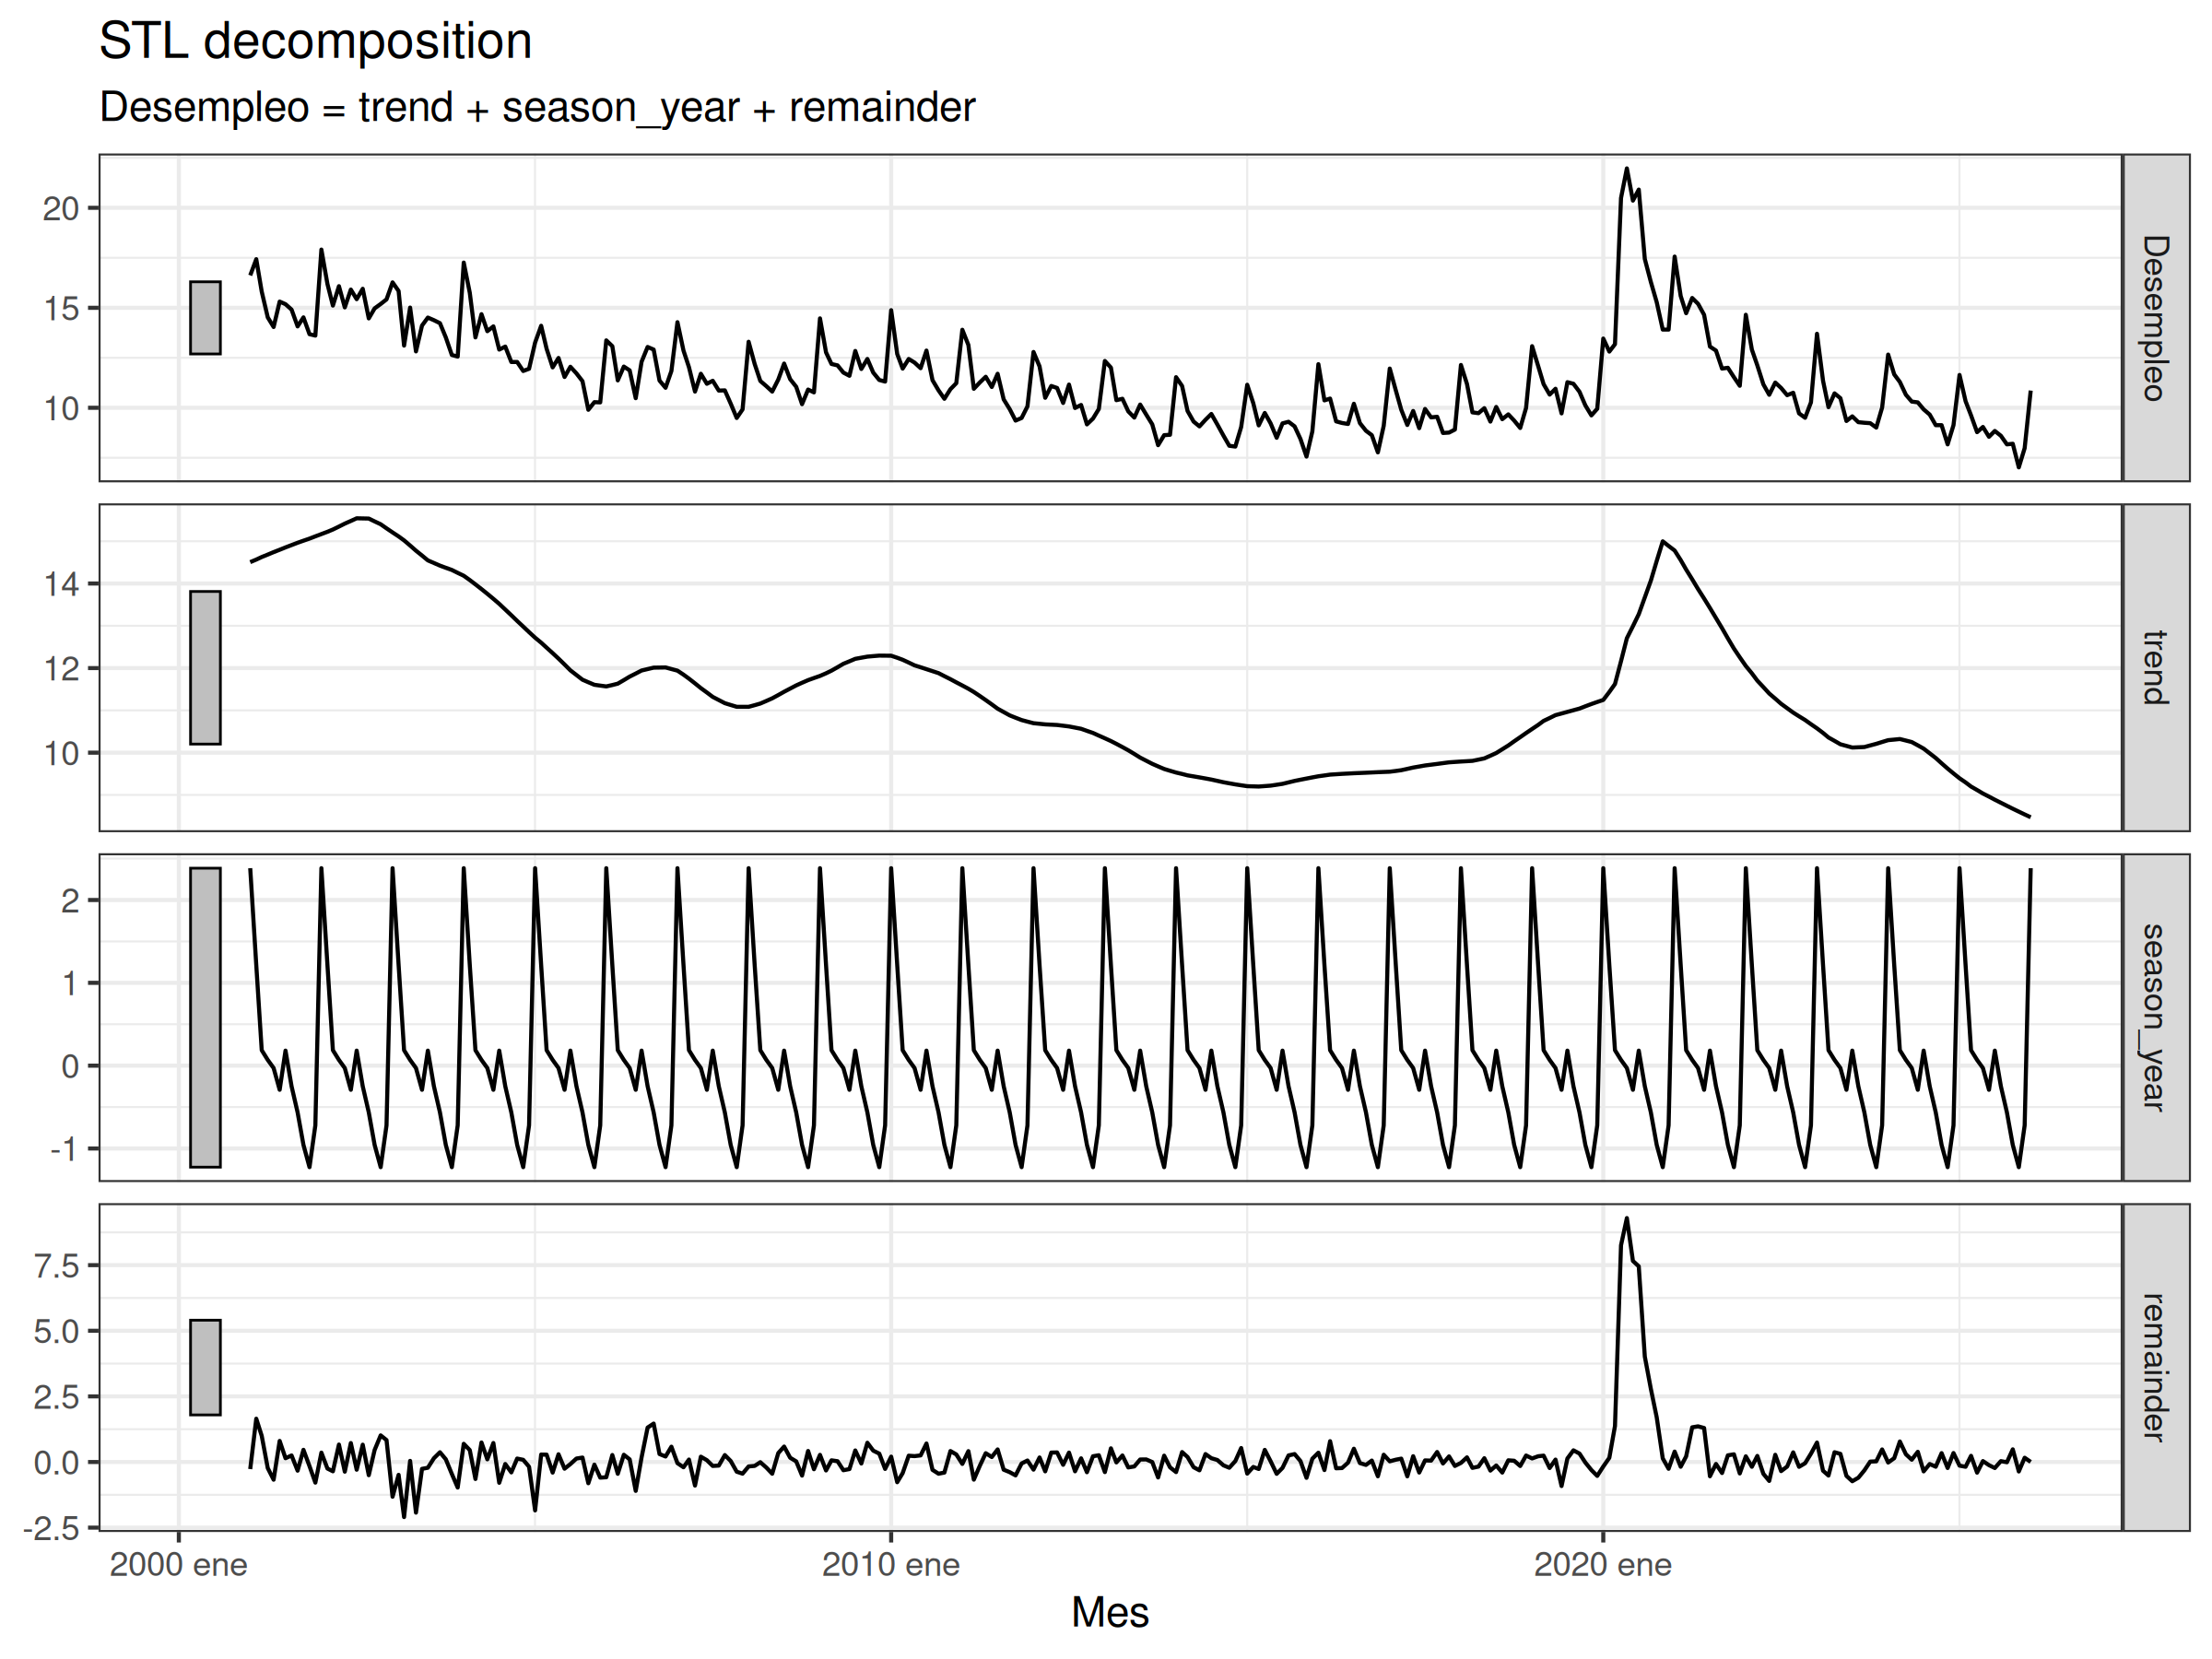

In [17]:
descomposicion <- desempleo |>
  model(stl = STL(Desempleo ~ season(window = "periodic"), robust = TRUE)) |>
  components()

descomposicion |> autoplot()

Mes,Desempleo,remainder
<mth>,<dbl>,<dbl>
2003 mar,13.11,-2.096402
2003 may,12.82,-1.927707
2020 abr,20.49,8.256730
2020 may,21.97,9.292948
2020 jun,20.36,7.661077
2020 jul,20.91,7.454308
2020 ago,17.44,4.016771
2020 sep,16.29,2.785679


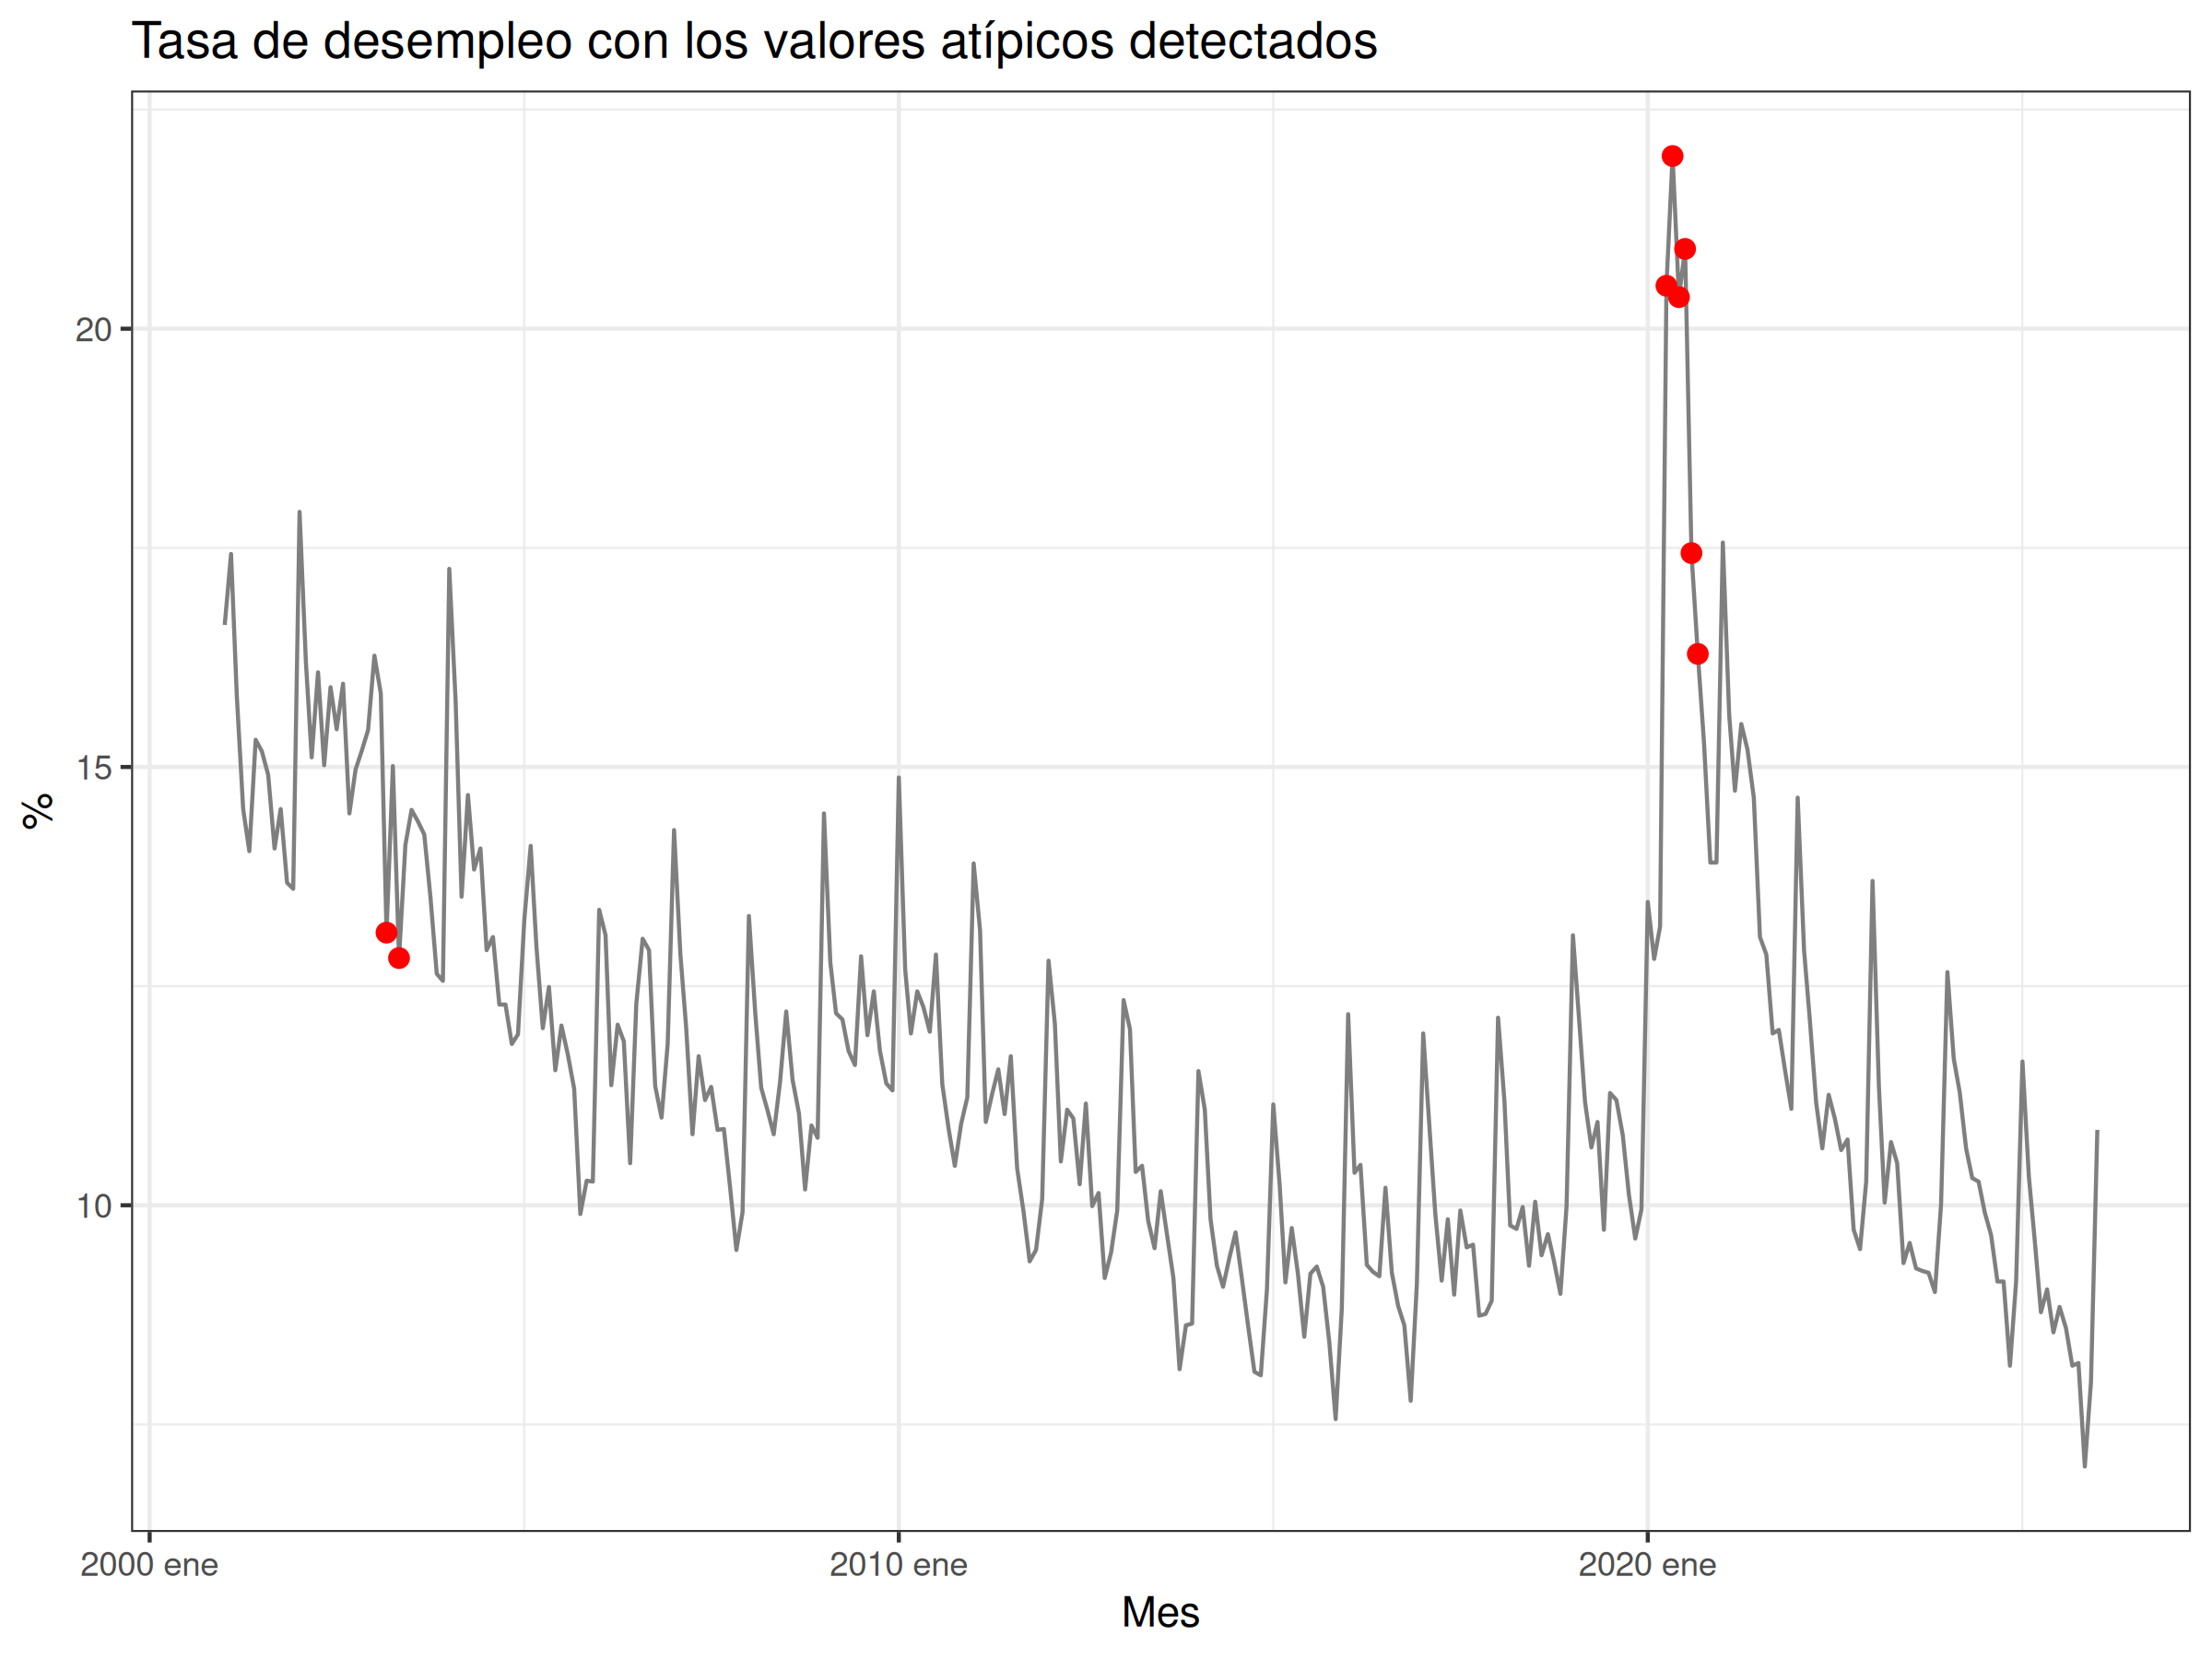

In [18]:
atipicos <- descomposicion |>
  filter(
    remainder < quantile(remainder, 0.25) - 3 * IQR(remainder) |
    remainder > quantile(remainder, 0.75) + 3 * IQR(remainder)
  )

atipicos |> as_tibble() |> select(Mes, Desempleo, remainder)

desempleo |>
  autoplot(Desempleo, colour = "grey50") +
  geom_point(data = atipicos, aes(x = Mes, y = Desempleo), colour = "red", size = 2) +
  labs(title = "Tasa de desempleo con los valores atípicos detectados", x = "Mes", y = "%")

**Interpretación**

- El método detecta como atípicos los meses de abril a septiembre de 2020, cuando la cuarentena por el COVID-19 elevó el desempleo por encima de lo que explican la tendencia y la estacionalidad.
- También detecta dos meses de 2003 con un desempleo más bajo que el esperado.
- Usar STL robusto es importante, porque así los valores atípicos no distorsionan la estimación de la tendencia y la estacionalidad, y quedan en el componente de residuo.

## Ejemplo 5. Series extrañas en el turismo de Australia

- Tenemos el número trimestral de viajes nocturnos en Australia (miles) para 76 regiones y 4 propósitos de viaje, es decir, 304 series.
- Seguimos el método de Hyndman y Athanasopoulos (2021, sección 4.5). Calculamos características de cada serie, como la fuerza de la tendencia y de la estacionalidad o la autocorrelación, y resumimos esas características con componentes principales. Las series que quedan lejos del resto en el gráfico de los dos primeros componentes son series inusuales.

In [19]:
tourism <- read_csv("../data/tourism.csv", show_col_types = FALSE) |>
  mutate(Quarter = yearquarter(ds)) |>
  select(Quarter, Region, State, Purpose, Trips = y) |>
  as_tsibble(index = Quarter, key = c(Region, State, Purpose))

# Características de cada serie
tourism_features <- tourism |>
  features(Trips, list(feat_stl, feat_acf, guerrero, unitroot_kpss, coef_hurst))

tourism_features

Region,State,Purpose,trend_strength,seasonal_strength_year,seasonal_peak_year,seasonal_trough_year,spikiness,linearity,curvature,⋯,acf10,diff1_acf1,diff1_acf10,diff2_acf1,diff2_acf10,season_acf1,lambda_guerrero,kpss_stat,kpss_pvalue,coef_hurst
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Adelaide,South Australia,Business,0.4638070,0.4069585,3,1,1.584763e+02,-5.3126332,71.5841775,⋯,0.13064555,-0.5196224,0.4625367,-0.6764291,0.7413571,0.20087547,0.514261559,0.22097756,0.10000000,0.5708798
Adelaide,South Australia,Holiday,0.5542186,0.6187292,1,2,9.167156e+00,49.0407477,78.7415934,⋯,0.37189807,-0.3426251,0.6143649,-0.4868330,0.5582436,0.35115135,-0.169464200,0.44856481,0.05622207,0.5575531
Adelaide,South Australia,Other,0.7457291,0.2020916,2,1,2.097208e+00,95.0866802,43.3978084,⋯,1.15359755,-0.4086204,0.3828913,-0.6751196,0.7923533,0.34178065,-0.227127985,1.40621121,0.01000000,0.8621758
Adelaide,South Australia,Visiting,0.4354986,0.4518154,1,3,5.612952e+01,34.5767879,71.3754529,⋯,0.29423657,-0.3936543,0.4522912,-0.5179591,0.4472958,0.34493047,0.870273608,0.26365274,0.10000000,0.5827218
Adelaide Hills,South Australia,Business,0.4641066,0.1793947,3,0,1.029723e-01,0.9684728,-3.2189933,⋯,0.13447305,-0.5795037,0.4145373,-0.7504035,0.7460039,-0.06280837,0.124177951,0.05954492,0.10000000,0.5547129
Adelaide Hills,South Australia,Holiday,0.5275212,0.2958543,2,1,1.766451e-01,10.4637483,23.9970281,⋯,0.31270988,-0.5361535,0.5002113,-0.7163426,0.9063143,0.20804204,0.245753995,0.47640318,0.04698127,0.6512539
Adelaide Hills,South Australia,Other,0.5934844,0.4038795,2,2,4.440051e-04,4.2772573,3.1857325,⋯,0.33016881,-0.2532267,0.3170873,-0.4574704,0.3922350,0.07453409,0.364876281,0.60455196,0.02222255,0.6719484
Adelaide Hills,South Australia,Visiting,0.4879478,0.2539251,0,3,6.497662e+00,34.2265062,-0.5294727,⋯,0.11678659,-0.4720059,0.2386155,-0.6255751,0.4077128,0.16977219,0.004143231,0.74943115,0.01000000,0.6532755
Alice Springs,Northern Territory,Business,0.5339263,0.2510186,0,1,1.693929e-01,23.7586211,19.5455893,⋯,0.36663436,-0.4995855,0.3805574,-0.6579956,0.5870383,0.31531357,0.561200578,0.80678573,0.01000000,0.7131274


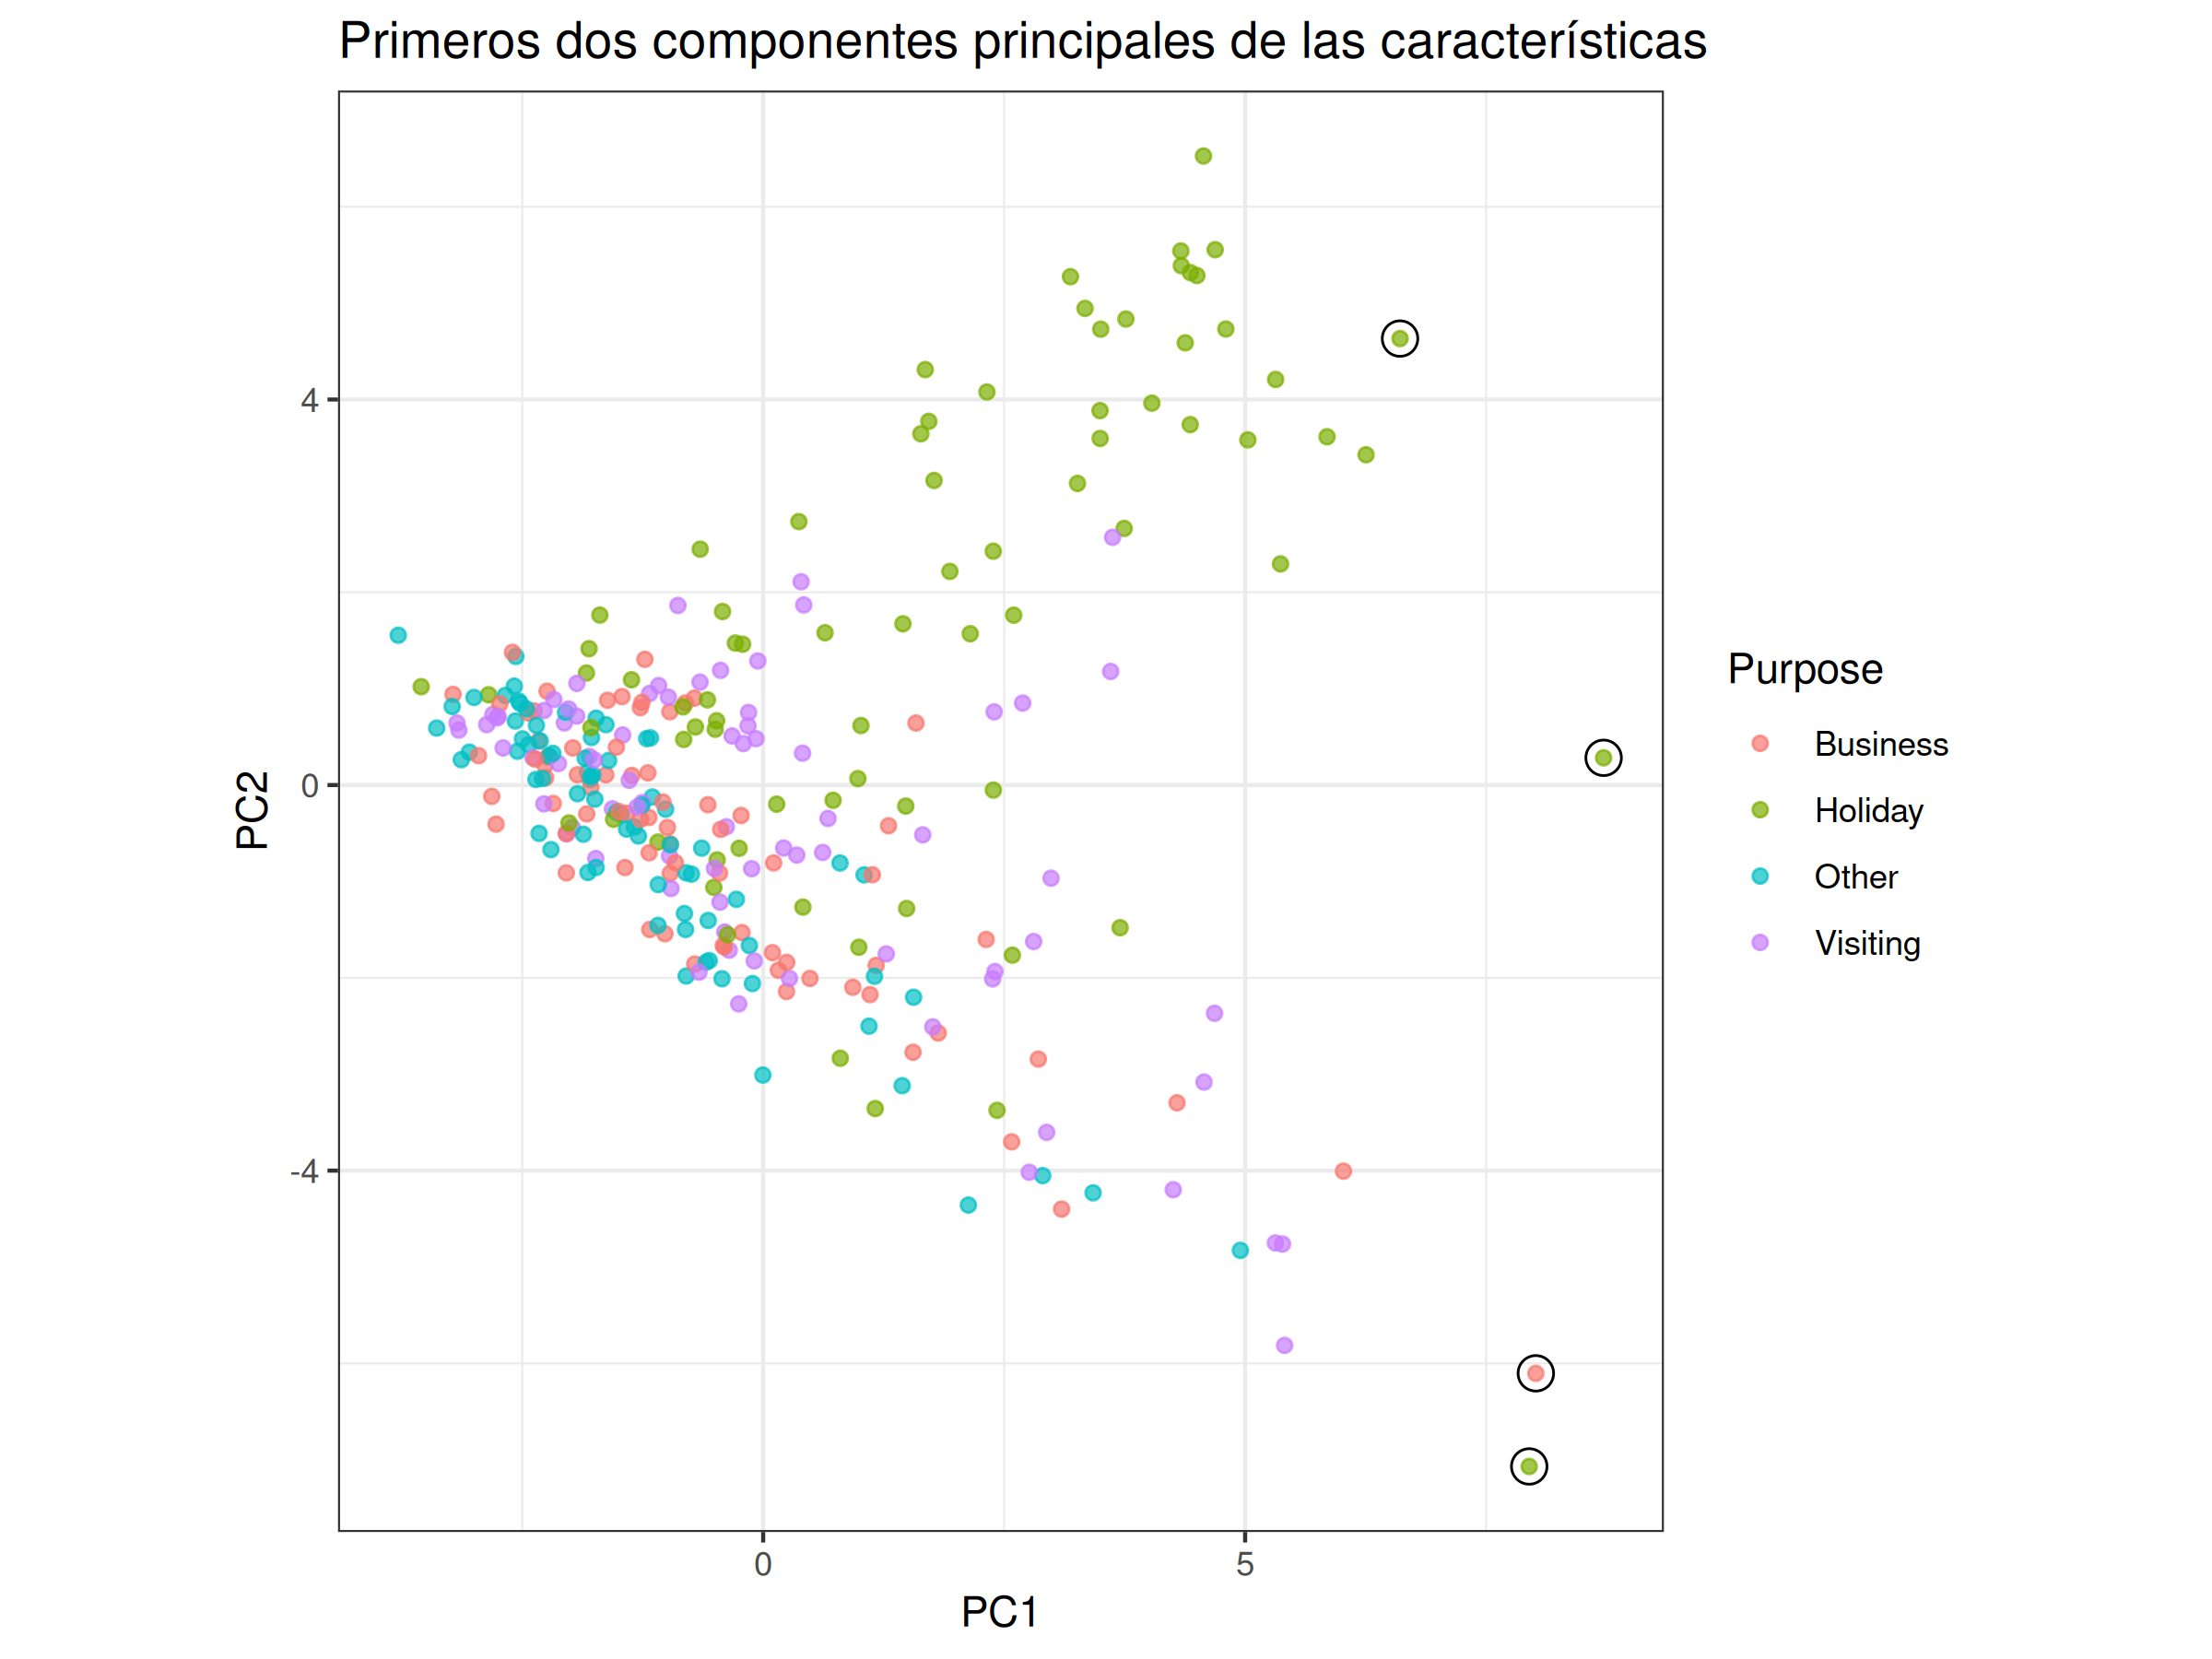

In [20]:
# Componentes principales de las características
pcs <- tourism_features |>
  select(-Region, -State, -Purpose) |>
  select(where(\(x) all(is.finite(x)))) |>
  prcomp(scale = TRUE) |>
  broom::augment(tourism_features)

# Las 4 series más alejadas del centro en los dos primeros componentes
inusuales <- pcs |>
  mutate(distancia = sqrt(.fittedPC1^2 + .fittedPC2^2)) |>
  slice_max(distancia, n = 4)

pcs |>
  ggplot(aes(x = .fittedPC1, y = .fittedPC2, colour = Purpose)) +
  geom_point(alpha = 0.7) +
  geom_point(data = inusuales, shape = 1, size = 4, colour = "black") +
  coord_equal() +
  labs(title = "Primeros dos componentes principales de las características", x = "PC1", y = "PC2")

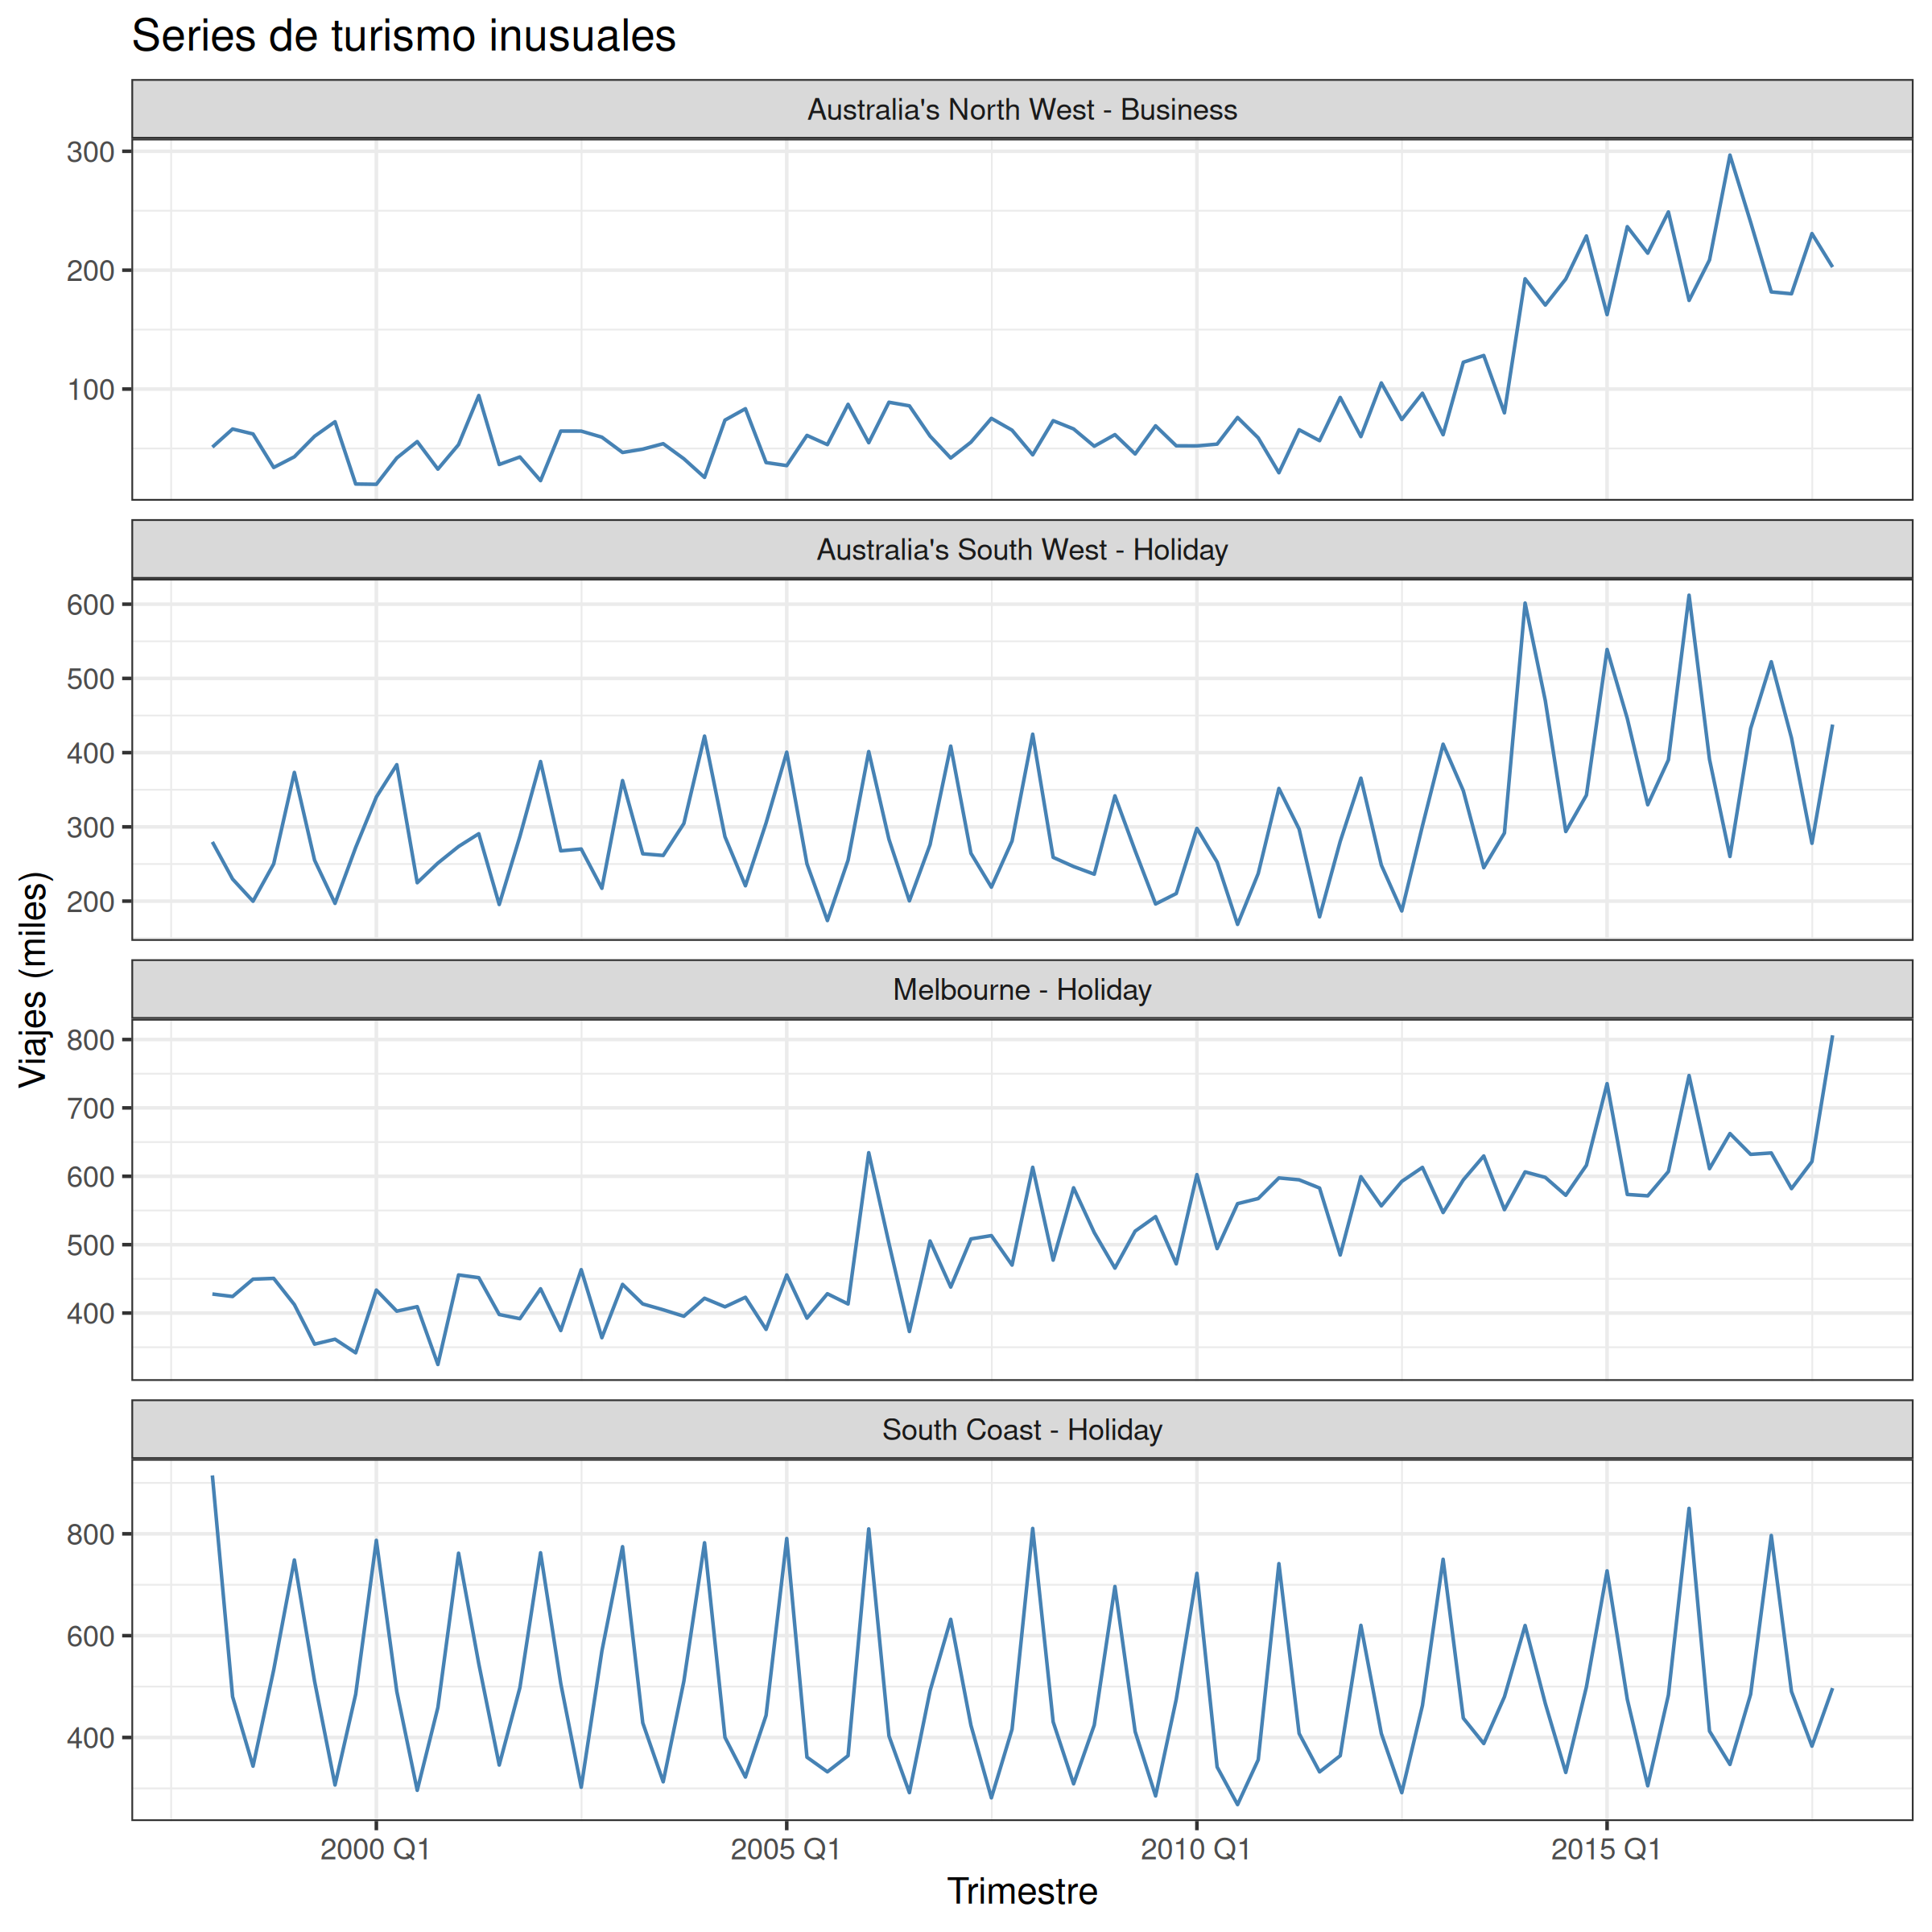

In [21]:
options(repr.plot.height = 8)
inusuales |>
  select(Region, State, Purpose) |>
  left_join(tourism, by = c("Region", "State", "Purpose"), multiple = "all") |>
  mutate(Serie = paste(Region, Purpose, sep = " - ")) |>
  ggplot(aes(x = Quarter, y = Trips)) +
  geom_line(colour = "steelblue") +
  facet_wrap(~ Serie, ncol = 1, scales = "free_y") +
  labs(title = "Series de turismo inusuales", x = "Trimestre", y = "Viajes (miles)")
options(repr.plot.height = 6)

**Interpretación**

- Las series de vacaciones (Holiday) se ubican arriba a la derecha del gráfico, porque tienen una estacionalidad más fuerte que las demás.
- Las cuatro series más alejadas del resto son inusuales por razones distintas.
    - En Australia's North West los viajes de negocios aumentan bruscamente desde 2012, un cambio que no se ve en las demás series.
    - En Australia's South West la estacionalidad de las vacaciones se vuelve mucho más marcada desde 2014.
    - En Melbourne los viajes de vacaciones tienen una tendencia creciente fuerte y poca estacionalidad, algo poco común en este tipo de viajes.
    - En South Coast la estacionalidad de las vacaciones es muy fuerte y estable durante todo el periodo.

## Ejemplo 6. Vigilancia de la tasa de desempleo de Colombia

- En la vigilancia queremos detectar una anomalía apenas llega el nuevo dato. Estimamos un modelo con la historia hasta diciembre de 2019 y, cada mes, comparamos el dato observado con el pronóstico a un paso del modelo.
- Con `refit(..., reestimate = FALSE)` aplicamos el modelo a toda la serie sin volver a estimar sus parámetros. Los residuos de innovación son los errores de pronóstico a un paso.
- Marcamos como anomalía un error mayor a 3 desviaciones estándar de los errores del periodo de estimación.

Mes,Desempleo,Pronostico,Error
<mth>,<dbl>,<dbl>,<dbl>
2020 mar,13.18,11.35,1.83
2020 abr,20.49,11.58,8.91
2020 may,21.97,14.96,7.01
2020 jun,20.36,16.93,3.43
2020 ago,17.44,20.31,-2.87
2020 sep,16.29,19.76,-3.47
2020 oct,15.28,18.11,-2.83
2020 nov,13.91,16.71,-2.80
2020 dic,13.91,16.12,-2.21


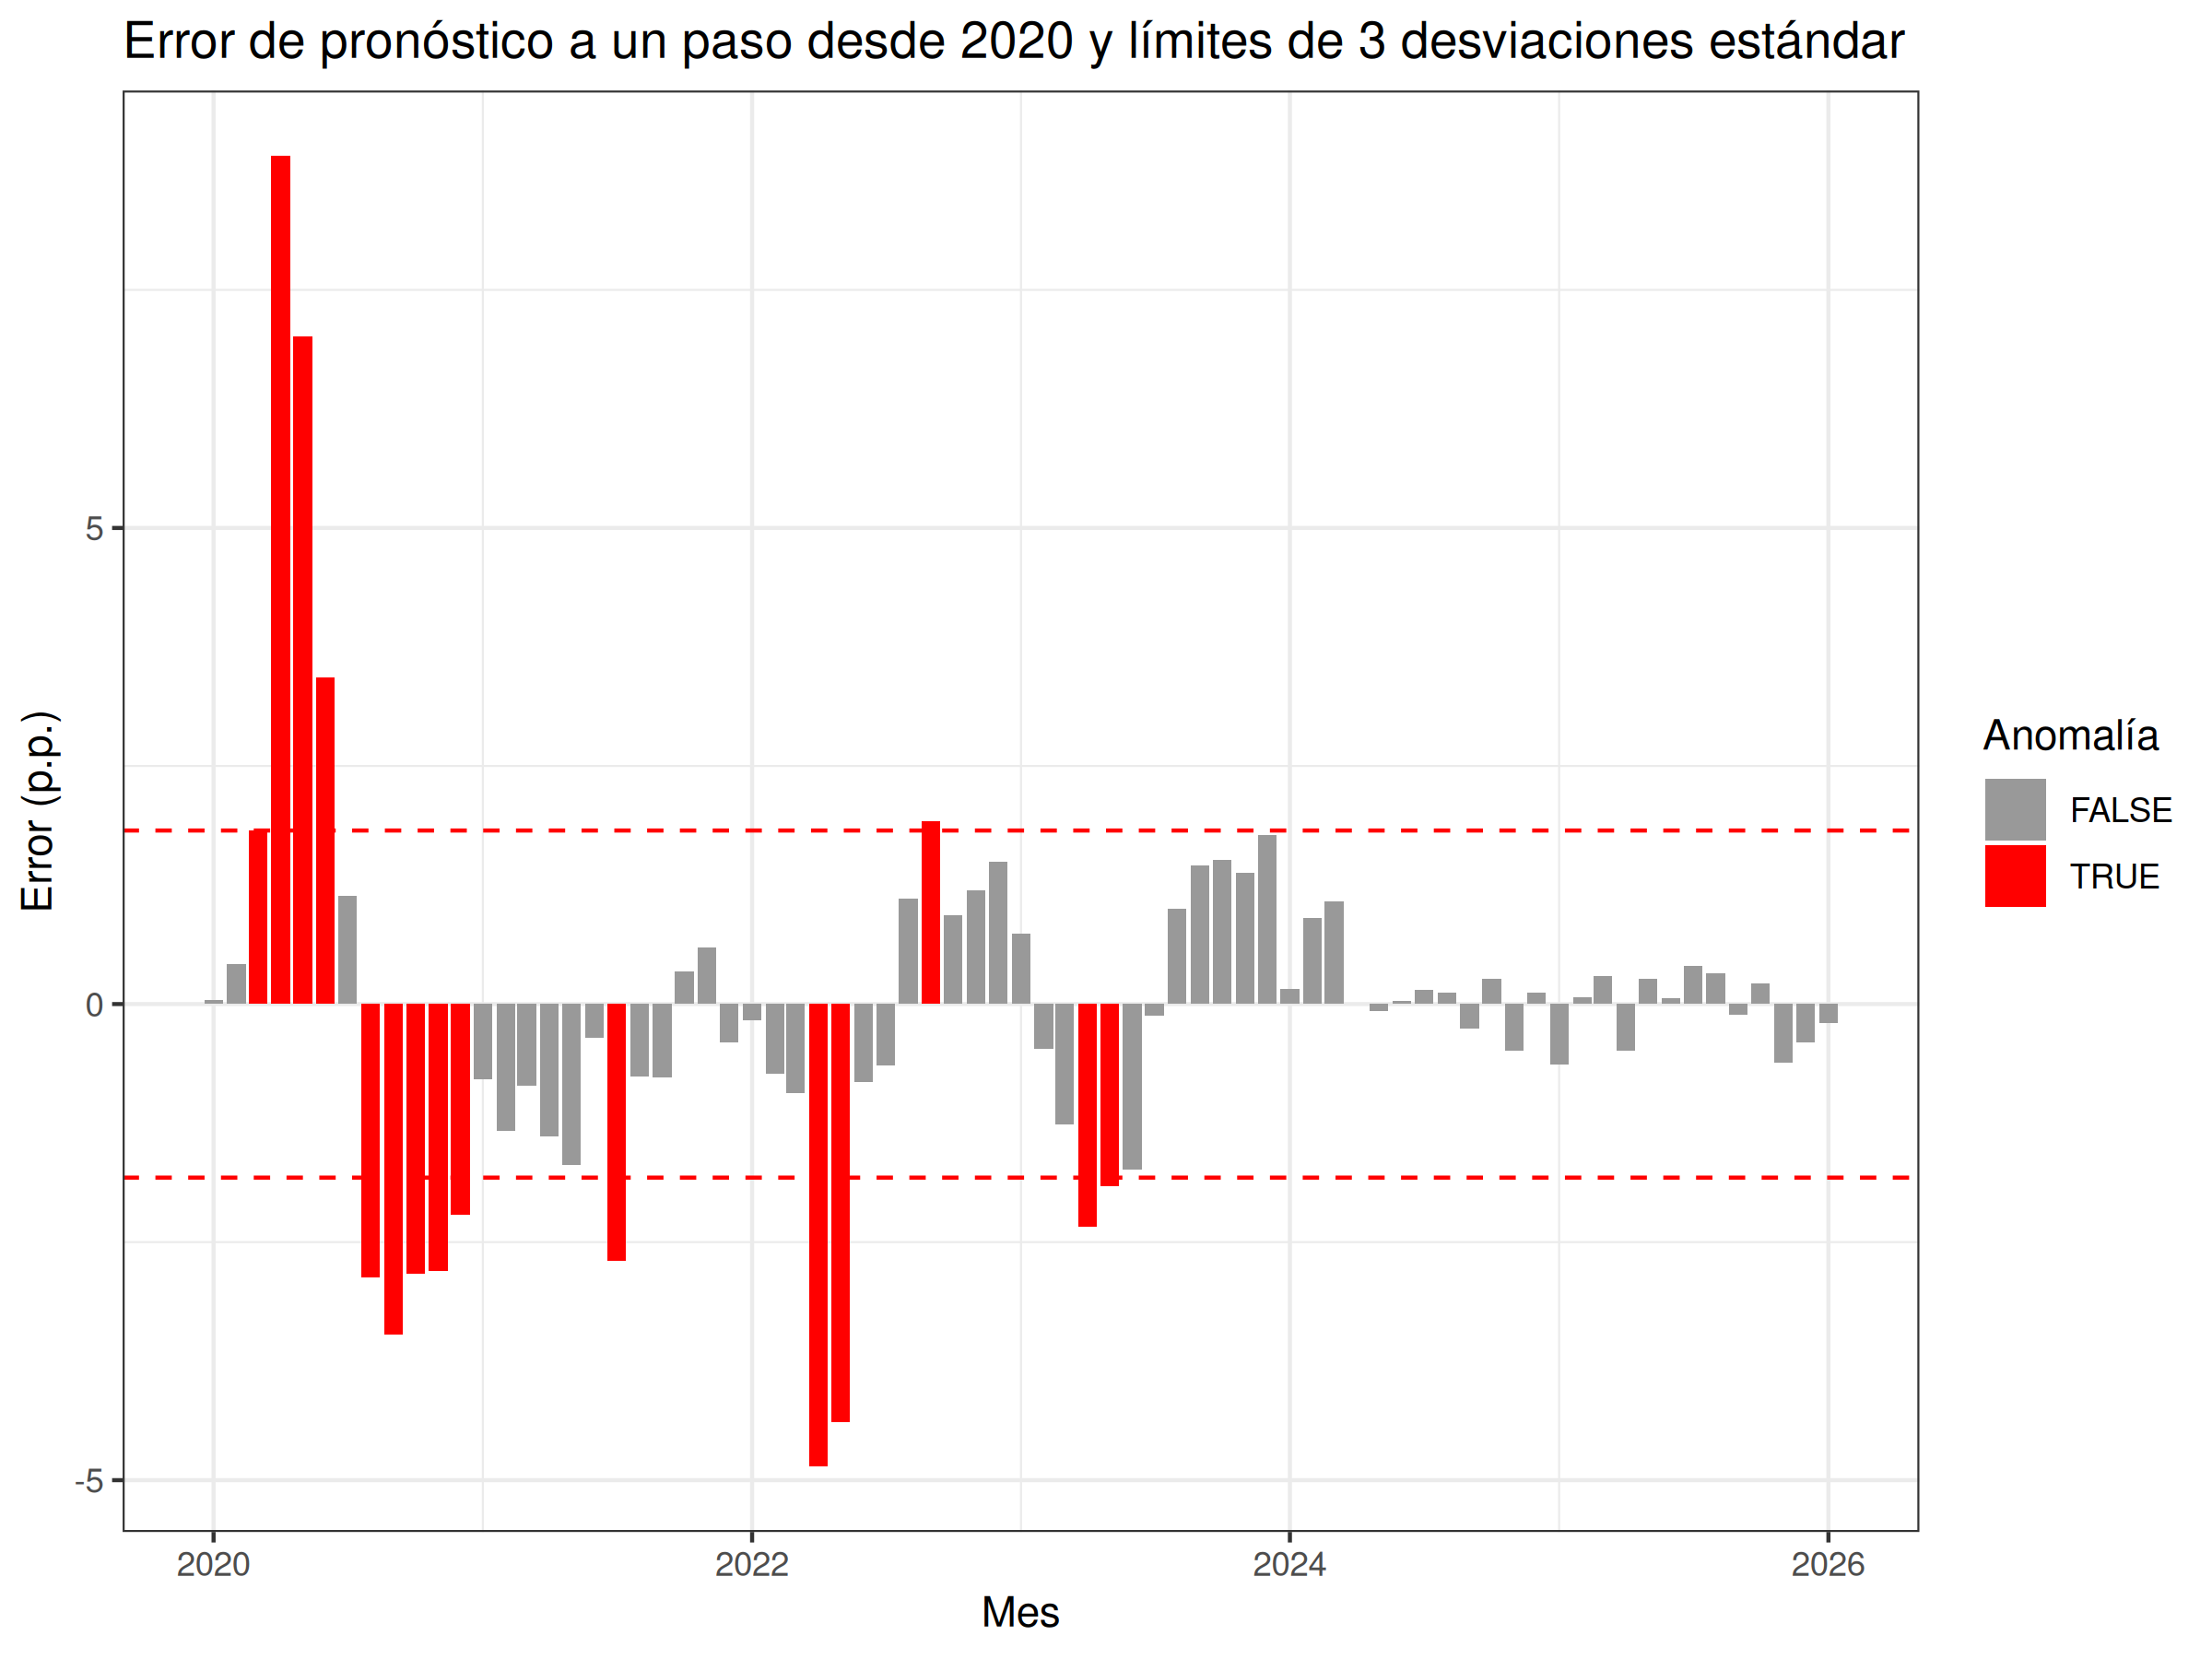

In [22]:
entrenamiento <- desempleo |> filter(Mes <= yearmonth("2019 Dec"))
fit_vigilancia <- entrenamiento |> model(ARIMA(Desempleo))

sigma <- sd(augment(fit_vigilancia)$.innov, na.rm = TRUE)

vigilancia <- fit_vigilancia |>
  refit(desempleo, reestimate = FALSE) |>
  augment() |>
  mutate(Anomalia = abs(.innov) > 3 * sigma)

vigilancia |>
  filter(Mes > yearmonth("2019 Dec")) |>
  ggplot(aes(x = as.Date(Mes), y = .innov)) +
  geom_col(aes(fill = Anomalia)) +
  geom_hline(yintercept = c(-3, 3) * sigma, linetype = "dashed", colour = "red") +
  scale_fill_manual(values = c("FALSE" = "grey60", "TRUE" = "red")) +
  labs(title = "Error de pronóstico a un paso desde 2020 y límites de 3 desviaciones estándar",
       x = "Mes", y = "Error (p.p.)", fill = "Anomalía")

vigilancia |>
  as_tibble() |>
  filter(Anomalia, Mes > yearmonth("2019 Dec")) |>
  select(Mes, Desempleo, Pronostico = .fitted, Error = .innov) |>
  mutate(across(where(is.numeric), \(x) round(x, 2)))

**Interpretación**

- La primera alarma aparece en marzo de 2020, cuando el desempleo ya fue mayor que lo esperado. En abril y mayo de 2020 los errores son mucho mayores que el límite de 3 desviaciones estándar.
- Después del choque el modelo sigue generando alarmas, porque no se volvió a estimar y la serie cambió de comportamiento. En la práctica, después de detectar un cambio estructural hay que volver a estimar el modelo para que la vigilancia siga siendo útil.

## Referencias

- Hyndman, R.J. y Athanasopoulos, G. (2021). *Forecasting: principles and practice*, 3rd edition. OTexts, Melbourne, Australia. [OTexts.com/fpp3](https://otexts.com/fpp3/)
- Turner, S.L., Karahalios, A., Forbes, A.B. et al. (2021). Comparison of six statistical methods for interrupted time series studies. *BMC Medical Research Methodology*, 21, 134.
- Cunningham, S. (2021). *Causal inference: The Mixtape*. Yale University Press.